# Analyse des retards et des causes, liaisons TGV

Ce notebook explore le jeu de données « Régularité mensuelle TGV par liaisons » pour comprendre les retards, les annulations et leurs causes. Il part d'une liaison (Paris Montparnasse - Nantes) puis prépare le passage à l'ensemble des liaisons.

## 1. Chargement et présentation des données

### 1.1 Imports et configuration

On importe les bibliothèques et on active les messages de suivi (logging).

In [1]:
import os

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from analyse_machoudi.utils.logging_config import setup_logging
from analyse_machoudi.utils.paths import get_data_path

setup_logging()

### 1.2 Chargement du fichier brut

On retrouve le fichier CSV dans le dossier `data` et on le charge dans le DataFrame `df`.

In [2]:
sncf_file_path = get_data_path()
print(sncf_file_path)
df = pd.read_csv(sncf_file_path, sep=";")

2026-11-06 23:36:35,435 | INFO | analyse_machoudi.utils.paths | Found data file: /home/machoudi/Documents/PROJETS/projet_sncf/data/regularite-mensuelle-tgv-aqst.csv


/home/machoudi/Documents/PROJETS/projet_sncf/data/regularite-mensuelle-tgv-aqst.csv


### 1.3 Aperçu du dataset

On regarde la taille, les types de colonnes, les valeurs manquantes, les premières lignes et le nombre de valeurs distinctes par colonne.

In [3]:
print("# dataset info")
display(df.info())
print("# dataset head")
display(df.head(10))
print("# dataset nunique")
display(df.nunique())

# dataset info
<class 'pandas.DataFrame'>
RangeIndex: 12907 entries, 0 to 12906
Data columns (total 26 columns):
 #   Column                                                                                       Non-Null Count  Dtype  
---  ------                                                                                       --------------  -----  
 0   Date                                                                                         12907 non-null  str    
 1   Service                                                                                      12907 non-null  str    
 2   Gare de départ                                                                               12907 non-null  str    
 3   Gare d'arrivée                                                                               12907 non-null  str    
 4   Durée moyenne du trajet                                                                      12907 non-null  int64  
 5   Nombre de circulations prévu

None

# dataset head


,Date,Service,Gare de départ,Gare d'arrivée,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Commentaire annulations,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,...,Nombre trains en retard > 15min,Retard moyen trains en retard > 15 (si liaison concurrencée par vol),Nombre trains en retard > 30min,Nombre trains en retard > 60min,Prct retard pour causes externes,Prct retard pour cause infrastructure,Prct retard pour cause gestion trafic,Prct retard pour cause matériel roulant,Prct retard pour cause gestion en gare et réutilisation de matériel,"Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"
0,2018-01,National,BORDEAUX ST JEAN,PARIS MONTPARNASSE,141,870,5,NaN,289,11.247809,...,110,6.511118,44,8,36.134454,31.092437,10.924370,15.966387,5.042017,0.840336
1,2018-01,National,LE MANS,PARIS MONTPARNASSE,56,406,1,NaN,213,8.479969,...,32,5.363539,9,4,20.000000,35.000000,16.666667,16.666667,8.333333,3.333333
2,2018-01,National,PARIS MONTPARNASSE,LA ROCHELLE VILLE,166,226,0,NaN,21,6.239683,...,11,2.938053,6,1,22.222222,27.777778,16.666667,16.666667,5.555556,11.111111
3,2018-01,National,PARIS MONTPARNASSE,NANTES,124,508,3,NaN,71,7.235211,...,39,5.292211,18,8,33.333333,22.222222,16.666667,20.370370,5.555556,1.851852
4,2018-01,National,POITIERS,PARIS MONTPARNASSE,94,472,4,NaN,224,6.784673,...,42,4.882372,10,0,15.789474,45.614035,19.298246,15.789474,1.754386,1.754386
5,2018-01,National,ST MALO,PARIS MONTPARNASSE,158,92,0,NaN,2,1.225000,...,6,4.763978,3,1,22.222222,66.666667,0.000000,11.111111,0.000000,0.000000
6,2018-01,National,TOULOUSE MATABIAU,PARIS MONTPARNASSE,257,184,0,NaN,23,11.221739,...,26,7.510507,12,3,59.090909,22.727273,4.545455,9.090909,4.545455,0.000000
7,2018-01,National,VANNES,PARIS MONTPARNASSE,156,278,1,NaN,168,5.120437,...,25,6.241487,11,3,24.137931,44.827586,20.689655,3.448276,3.448276,3.448276
8,2018-01,National,REIMS,PARIS EST,46,230,1,NaN,93,7.432796,...,20,3.538937,3,0,17.948718,41.025641,20.512821,5.128205,0.000000,15.384615
9,2018-01,National,DOUAI,PARIS NORD,77,197,3,NaN,39,8.032906,...,10,5.046907,5,3,36.363636,18.181818,22.727273,18.181818,4.545455,0.000000


# dataset nunique


Date                                                                                             105
Service                                                                                            2
Gare de départ                                                                                    59
Gare d'arrivée                                                                                    59
Durée moyenne du trajet                                                                          411
Nombre de circulations prévues                                                                   908
Nombre de trains annulés                                                                         192
Commentaire annulations                                                                            0
Nombre de trains en retard au départ                                                             460
Retard moyen des trains en retard au départ                                                

### 1.4 Présentation du dataset

Ce jeu de données décrit la régularité mensuelle des TGV, liaison par liaison, sur le réseau national français et sur les services internationaux. Il est publié par SNCF Voyageurs en open data et couvre la période 2018 à ce jour.

Chaque ligne correspond à une liaison, c'est-à-dire un trajet entre une gare de départ et une gare d'arrivée, pour un mois donné.

On peut regrouper les colonnes en six familles :
- **Identification** : la date, le service (National ou International), les gares de départ et d'arrivée, et la durée moyenne du trajet en minutes.
- **Volume de circulations par mois** : le nombre de circulations prévues et le nombre de trains annulés.
- **Retards au départ** : le nombre de trains en retard, le retard moyen de ces trains et le retard moyen de tous les trains.
- **Retards à l'arrivée** : les mêmes mesures, relevées au terminus.
- **Gravité des retards** : le nombre de trains en retard de plus de 15, 30 et 60 minutes.
- **Causes** : six pourcentages qui répartissent les retards entre causes externes, infrastructure, gestion du trafic, matériel roulant, gestion en gare et prise en compte des voyageurs.

On peut aussi remarquer que ce jeu de données contient des colonnes de commentaires en texte libre, mais presque toutes vides.

Selon la SNCF, un train est à l'heure si son retard au terminus reste inférieur à 5, 10 ou 15 minutes, selon que le trajet dure moins de 1h30, entre 1h30 et 3h, ou plus de 3h. Enfin, un même TGV peut compter dans plusieurs liaisons, on ne peut donc pas additionner les liaisons pour obtenir une régularité globale (source https://ressources.data.sncf.com/explore/dataset/regularite-mensuelle-tgv-aqst/information/?sort=-retard_moyen_depart&dataChart=eyJxdWVyaWVzIjpbeyJjaGFydHMiOlt7InR5cGUiOiJzcGxpbmUiLCJmdW5jIjoiQVZHIiwieUF4aXMiOiJwcmN0X2NhdXNlX2V4dGVybmUiLCJzY2llbnRpZmljRGlzcGxheSI6dHJ1ZSwiY29sb3IiOiJyYW5nZS1TZXQxIn1dLCJ4QXhpcyI6ImRhdGUiLCJtYXhwb2ludHMiOiIiLCJ0aW1lc2NhbGUiOiJtb250aCIsInNvcnQiOiIiLCJzZXJpZXNCcmVha2Rvd24iOiJnYXJlX2Fycml2ZWUiLCJjb25maWciOnsiZGF0YXNldCI6InJlZ3VsYXJpdGUtbWVuc3VlbGxlLXRndi1hcXN0Iiwib3B0aW9ucyI6eyJzb3J0IjoiLXJldGFyZF9tb3llbl9kZXBhcnQifX19XSwiZGlzcGxheUxlZ2VuZCI6dHJ1ZSwiYWxpZ25Nb250aCI6dHJ1ZSwidGltZXNjYWxlIjoiIn0%3D)

## 2. Étude d'une liaison : Paris Montparnasse - Nantes

### 2.1 Extraction de la liaison et couverture

On isole la liaison Paris Montparnasse - Nantes, puis on vérifie qu'elle est présente tous les mois, sans doublon.

In [4]:
df_paris_nantes = df.query(
    "`Gare de départ` == 'PARIS MONTPARNASSE' & `Gare d'arrivée` == 'NANTES'"
)
print(len(df_paris_nantes))
print(df["Date"].nunique())

105
105


In [5]:
months_all = df["Date"].unique()
months_route = df_paris_nantes["Date"].unique()

print(
    f"Months in the file: {len(months_all)} (from {months_all.min()} to {months_all.max()})"
)
print(
    f"Months for Paris to Nantes: {len(months_route)} (from {months_route.min()} to {months_route.max()})"
)
print(f"Months missing for the route: {set(months_all) - set(months_route)}")
print(f"Duplicated months for the route: {df_paris_nantes['Date'].duplicated().sum()}")

cols = [
    "Date",
    "Nombre de circulations prévues",
    "Nombre de trains annulés",
    "Nombre de trains en retard à l'arrivée",
    "Retard moyen de tous les trains à l'arrivée",
]
df_paris_nantes.sort_values("Date")[cols].head(12)

Months in the file: 105 (from 2018-01 to 2026-09)
Months for Paris to Nantes: 105 (from 2018-01 to 2026-09)
Months missing for the route: set()
Duplicated months for the route: 0


,Date,Nombre de circulations prévues,Nombre de trains annulés,Nombre de trains en retard à l'arrivée,Retard moyen de tous les trains à l'arrivée
3,2018-01,508,3,58,5.292211
153,2018-02,465,22,89,10.819639
338,2018-03,512,13,50,3.593988
500,2018-04,506,160,53,5.060356
523,2018-05,532,141,62,9.039855
654,2018-06,540,74,65,7.392775
862,2018-07,473,56,71,9.088569
1013,2018-08,405,6,44,3.530117
1042,2018-09,495,2,68,4.303313
1202,2018-10,482,1,50,4.137041


La liaison Paris Montparnasse - Nantes est complète : 105 mois, de janvier 2018 à septembre 2026, sans mois manquant ni doublon.

### 2.2 Question posée et indicateurs

**Question :** La liaison Paris - Nantes a-t-elle un comportement stable ou erratique dans le temps, et qu’est-ce qui la perturbe ?


Pour répondre à cette question, on déterminera le taux d'annulation mensuel et le taux du nombre de trains en retard à l'arrivée.

Le taux de retard est calculé sur les trains qui ont réellement circulé (trains prévus moins trains annulés), car un train annulé ne peut pas être en retard. La colonne s'appelle `taux_retard_arrivee`. On ajoute aussi l'année et le mois pour les heatmaps.

In [6]:
df_paris_nantes = df_paris_nantes.copy()
df_paris_nantes["Date"] = pd.to_datetime(df_paris_nantes["Date"])
df_paris_nantes = df_paris_nantes.sort_values("Date").reset_index(drop=True)

df_paris_nantes["taux_annulation"] = (
    df_paris_nantes["Nombre de trains annulés"]
    / df_paris_nantes["Nombre de circulations prévues"]
)
df_paris_nantes["taux_retard_arrivee"] = df_paris_nantes[
    "Nombre de trains en retard à l'arrivée"
] / (
    df_paris_nantes["Nombre de circulations prévues"]
    - df_paris_nantes["Nombre de trains annulés"]
)

df_paris_nantes["annee"] = df_paris_nantes["Date"].dt.year
df_paris_nantes["mois"] = df_paris_nantes["Date"].dt.month

### 2.3 Évolution mensuelle

On trace les deux taux mois par mois, de 2018 à 2026, pour voir le niveau habituel et les mois qui s'en écartent.

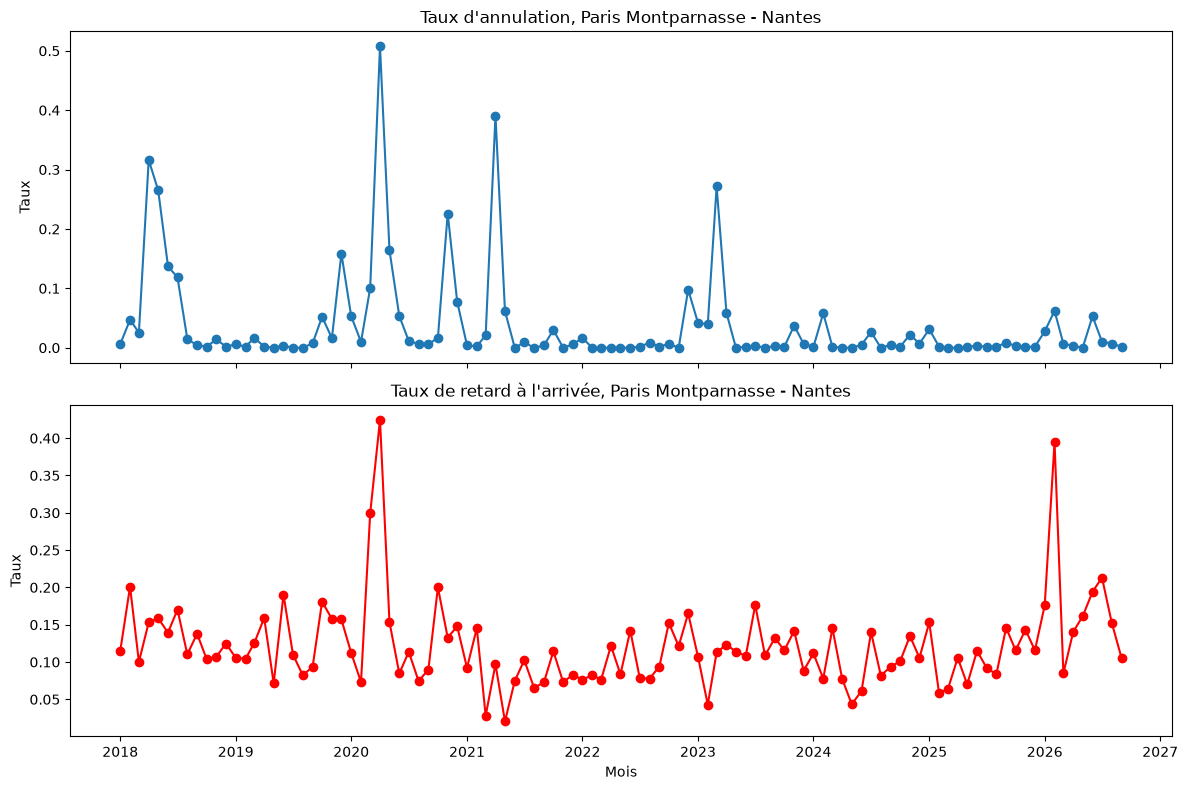

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(df_paris_nantes["Date"], df_paris_nantes["taux_annulation"], marker="o")
axes[0].set_title("Taux d'annulation, Paris Montparnasse - Nantes")
axes[0].set_ylabel("Taux")

axes[1].plot(
    df_paris_nantes["Date"],
    df_paris_nantes["taux_retard_arrivee"],
    marker="o",
    color="r",
)
axes[1].set_title("Taux de retard à l'arrivée, Paris Montparnasse - Nantes")
axes[1].set_ylabel("Taux")
axes[1].set_xlabel("Mois")

plt.tight_layout()
plt.show()

### 2.4 Vue année × mois

On range chaque taux dans un tableau (une ligne par année, une colonne par mois) pour voir si les pics reviennent aux mêmes mois d'une année à l'autre.

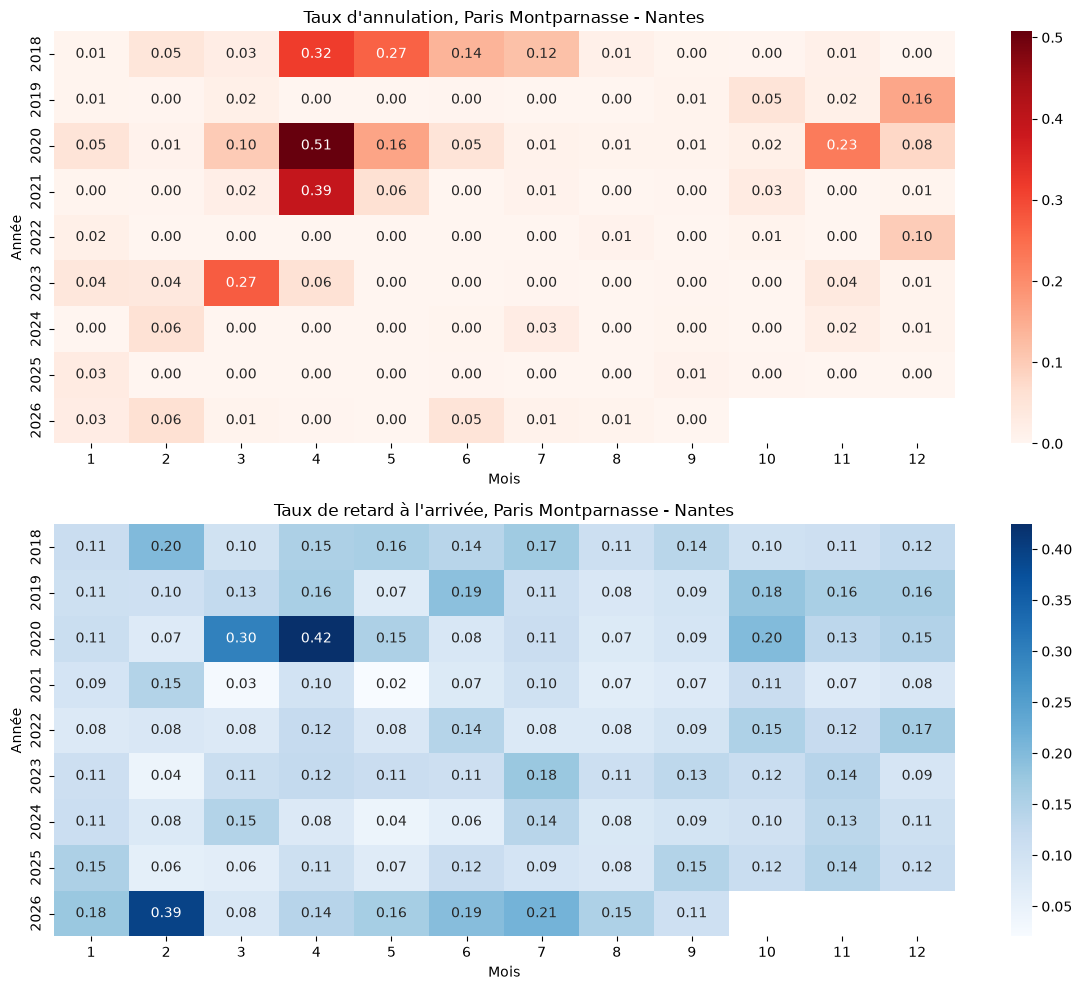

In [8]:
table_annulation = df_paris_nantes.pivot(
    index="annee", columns="mois", values="taux_annulation"
)
table_retard = df_paris_nantes.pivot(
    index="annee", columns="mois", values="taux_retard_arrivee"
)

# display(table_annulation.head(10))
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

sns.heatmap(table_annulation, annot=True, fmt=".2f", cmap="Reds", ax=axes[0])
axes[0].set_title("Taux d'annulation, Paris Montparnasse - Nantes")
axes[0].set_xlabel("Mois")
axes[0].set_ylabel("Année")

sns.heatmap(table_retard, annot=True, fmt=".2f", cmap="Blues", ax=axes[1])
axes[1].set_title("Taux de retard à l'arrivée, Paris Montparnasse - Nantes")
axes[1].set_xlabel("Mois")
axes[1].set_ylabel("Année")

plt.tight_layout()
plt.show()

### 2.5 Lecture des figures

D'après la figure relative à l'évolution mensuelle du taux d'annulation de 2018 à 2026, les annulations sont presque toujours proches de zéro, avec quelques pics isolés. La figure représentant le taux d'annulation par année et par mois situe ces pics. Le premier a lieu d'avril à juillet 2018, avec 12 % à 32 % des trains prévus annulés. On observe ensuite 16 % en décembre 2019, puis 2020 qui est l'année la plus touchée, avec 51 % en avril et 23 % en novembre. Avril 2021 atteint encore 39 %, décembre 2022 10 % et mars 2023 27 %. Ces taux sont très élevés certains mois et nuls d'autres, ce qui indique des événements ponctuels plutôt qu'une saisonnalité. Les années 2024 et 2025 sont presque toujours proches de zéro.

Le taux de retard à l'arrivée est calculé sur les trains qui ont réellement circulé, soit les trains prévus moins les trains annulés. Il indique la part des trains partis qui arrivent en retard à leur terminus.

D'après la figure relative à l'évolution mensuelle du taux de retard à l'arrivée, le retard est beaucoup plus stable et se situe le plus souvent autour de 10 % des trains circulés. La figure représentant le taux de retard à l'arrivée par année et par mois fait ressortir mars 2020 (30 %), avril 2020 (42 %) et février 2026 (39 %). Aucune colonne ne reste foncée d'une année à l'autre, il n'y a donc pas de saisonnalité nette. Le retard reste aussi élevé de mai à juillet 2026, entre 16 % et 21 %.

Les pics d'annulation et de retard ne se produisent pas aux mêmes mois, seul avril 2020 est élevé pour les deux. Les annulations semblent donc ponctuelles, alors que le retard est plutôt répétitif, à un niveau modéré. Cette analyse ne porte que sur la liaison Paris - Nantes.

## 3. Causes de retard sur Paris Montparnasse - Nantes

### 3.1 Contrôle des pourcentages

On récupère les six colonnes de causes et on vérifie que leurs pourcentages somment à 100 chaque mois.

In [9]:
cause_cols = [col for col in df.columns if col.startswith("Prct retard pour")]
print(len(cause_cols))
print(cause_cols)

df_paris_nantes["somme_causes"] = df_paris_nantes[cause_cols].sum(axis=1)
print(df_paris_nantes["somme_causes"].describe())

ecart = df_paris_nantes[(df_paris_nantes["somme_causes"] - 100).abs() > 1]
print(f"Mois dont la somme s'écarte de 100 : {len(ecart)}")
display(ecart[["Date", "Nombre de trains en retard à l'arrivée", "somme_causes"]])

6
['Prct retard pour causes externes', 'Prct retard pour cause infrastructure', 'Prct retard pour cause gestion trafic', 'Prct retard pour cause matériel roulant', 'Prct retard pour cause gestion en gare et réutilisation de matériel', 'Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)']
count    1.050000e+02
mean     1.000000e+02
std      6.230256e-09
min      1.000000e+02
25%      1.000000e+02
50%      1.000000e+02
75%      1.000000e+02
max      1.000000e+02
Name: somme_causes, dtype: float64
Mois dont la somme s'écarte de 100 : 0


,Date,Nombre de trains en retard à l'arrivée,somme_causes


### 3.2 Vue globale des causes

On convertit les pourcentages en nombres de trains, on les additionne par cause sur les 105 mois, puis on calcule la part de chaque cause.

In [ ]:
noms_courts = [
    "Externes",
    "Infrastructure",
    "Gestion du trafic",
    "Matériel roulant",
    "Gestion en gare",
    "Prise en compte des voyageurs",
]

In [11]:
volumes = (
    df_paris_nantes[cause_cols].mul(
        df_paris_nantes["Nombre de trains en retard à l'arrivée"], axis=0
    )
    / 100
)

total_par_cause = volumes.sum()
parts = 100 * total_par_cause / total_par_cause.sum()

resume_causes = pd.DataFrame(
    {
        "cause": noms_courts,
        "trains": total_par_cause.values,
        "part_%": parts.values,
    }
).sort_values("part_%", ascending=False)

display(resume_causes)

print(volumes.shape)
print(volumes.isna().sum().sum())
print(resume_causes["part_%"].sum())

,cause,trains,part_%
0,Externes,1927.984851,30.578665
1,Infrastructure,1270.235420,20.146478
3,Matériel roulant,1031.218806,16.355572
2,Gestion du trafic,1002.760748,15.904215
4,Gestion en gare,558.251270,8.854104
5,Prise en compte des voyageurs,514.548905,8.160966


(105, 6)
0
100.0


Dans cette partie, nous voulons savoir quelles causes expliquent le plus souvent les retards à l'arrivée sur cette liaison. Nous disposons pour chaque mois, la répartition des retards en six causes sous forme de pourcentages. Pour obtenir une vue globale sur les 105 mois ( de Janvier 2018 à Septembre 2026), nous avons converti ces pourcentages en nombres de trains, en les multipliant par le nombre de trains en retard à l'arrivée du mois. Nous avons ensuite additionné ces nombres pour chaque cause, puis divisé chaque total par la somme des six. Cette méthode évite de faire la moyenne de pourcentages calculés sur des mois qui n'ont pas le même nombre de retards.

On remarque que, sur la liaison Paris - Nantes, les causes externes représentent près d'un tiers des retards à l'arrivée (31 %), suivies des causes liées à l'infrastructure (20 %). Le matériel roulant et la gestion du trafic pèsent chacun environ 16 %, la gestion en gare et la prise en compte des voyageurs moins de 9 % chacune.

### 3.3 Vue mensuelle des causes

On regarde comment la répartition des causes évolue mois par mois. Le graphique empilé donne une vue d'ensemble, et les six courbes permettent de comparer chaque cause à sa part globale.

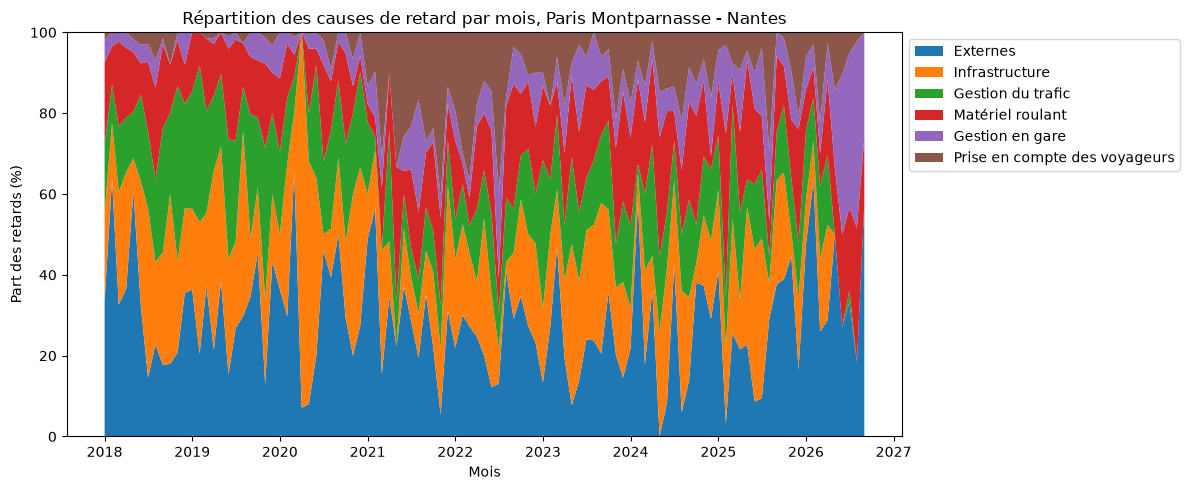

In [12]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.stackplot(
    df_paris_nantes["Date"],
    df_paris_nantes[cause_cols].T,
    labels=noms_courts,
)
ax.set_ylim(0, 100)
ax.set_title("Répartition des causes de retard par mois, Paris Montparnasse - Nantes")
ax.set_xlabel("Mois")
ax.set_ylabel("Part des retards (%)")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

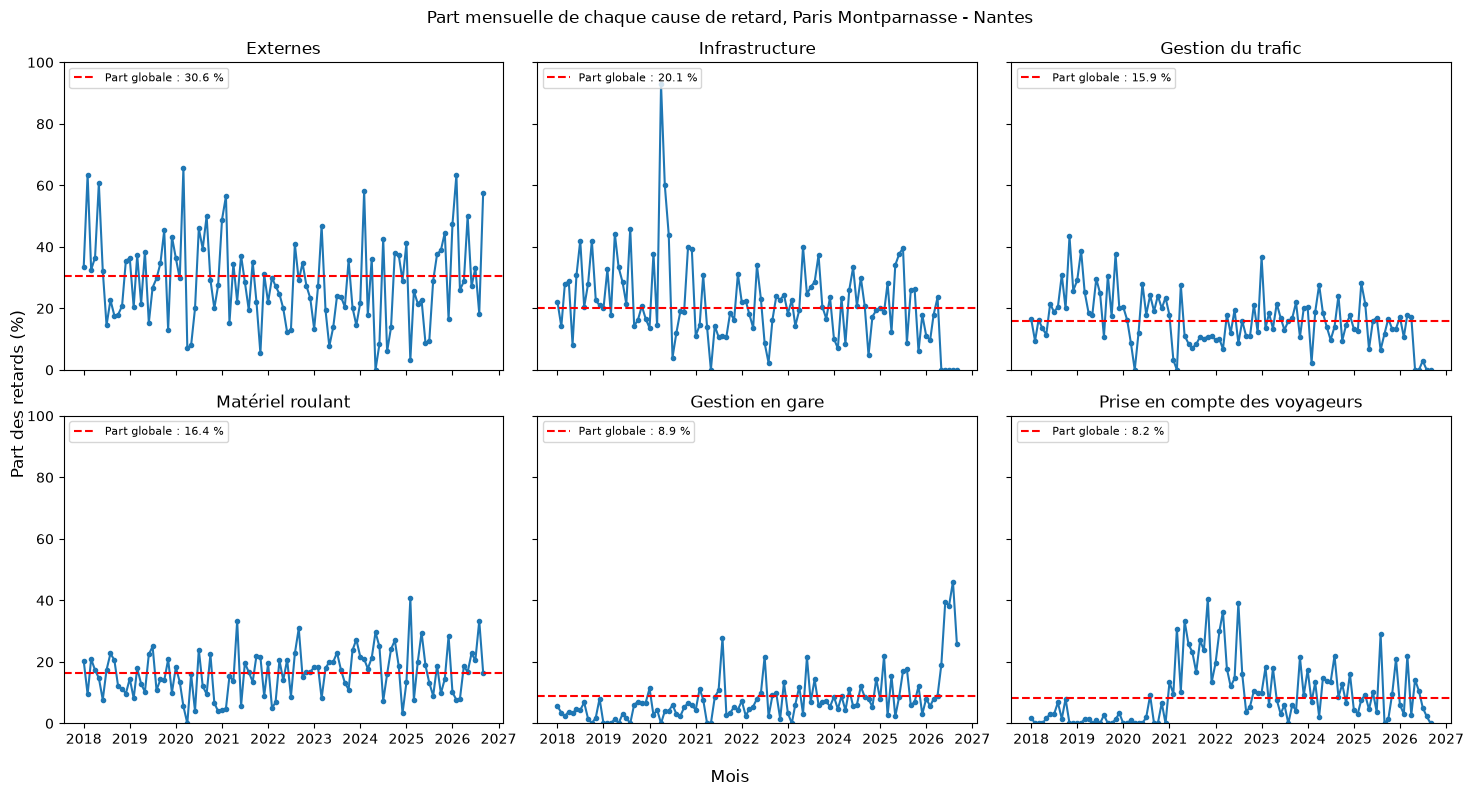

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)

for ax, col, nom, part in zip(axes.flatten(), cause_cols, noms_courts, parts):
    ax.plot(df_paris_nantes["Date"], df_paris_nantes[col], marker="o", markersize=3)
    ax.axhline(part, color="red", linestyle="--", label=f"Part globale : {part:.1f} %")
    ax.set_title(nom)
    ax.set_ylim(0, 100)
    ax.legend(loc="upper left", fontsize=8)

fig.supxlabel("Mois")
fig.supylabel("Part des retards (%)")
fig.suptitle("Part mensuelle de chaque cause de retard, Paris Montparnasse - Nantes")
plt.tight_layout()
plt.show()

### 3.4 Les derniers mois de la série

On regarde le nombre de retards et la répartition des causes sur les six derniers mois, pour vérifier que les variations récentes reposent sur un nombre de retards suffisant.

In [14]:
colonnes = ["Date", "Nombre de trains en retard à l'arrivée"] + cause_cols
tableau = df_paris_nantes.sort_values("Date")[colonnes].tail(6)
tableau.columns = ["Date", "Retards à l'arrivée"] + noms_courts
display(tableau)

,Date,Retards à l'arrivée,Externes,Infrastructure,Gestion du trafic,Matériel roulant,Gestion en gare,Prise en compte des voyageurs
99,2026-04-01,84,28.749112,23.560768,17.324094,18.656716,9.044065,2.665245
100,2026-05-01,95,50.000000,0.000000,0.000000,16.666667,19.122807,14.210526
101,2026-06-01,111,27.123402,0.000000,0.000000,22.820029,39.580976,10.475592
102,2026-07-01,123,33.204781,0.000000,2.968869,20.450281,38.263498,5.112570
103,2026-08-01,85,18.300654,0.000000,0.000000,33.333333,46.078431,2.287582
104,2026-09-01,63,57.589286,0.000000,0.000000,16.468254,25.942460,0.000000


### 3.5 Lecture des figures et conclusions

La figure "Part mensuelle de chaque cause de retard" montre, pour chaque cause, sa part du mois par rapport à sa part globale. Les causes externes et le matériel roulant oscillent de part et d'autre de leur ligne. La gestion en gare reste le plus souvent sous 10 % jusqu'en 2025, puis atteint entre 38 % et 46 % de juin à août 2026, sur des mois comptant entre 85 et 123 retards. Sur la même période, l'infrastructure et la gestion du trafic sont à 0 % ou presque. La prise en compte des voyageurs est proche de 0 jusqu'à fin 2020, puis dépasse sa part globale de 2021 à 2023.

Au vu des résultats, on remarque que sur la liaison Paris - Nantes, les causes externes dominent sur l'ensemble de la période (31 % des retards à l'arrivée), devant l'infrastructure (20 %). Cette répartition globale varie toutefois fortement d'un mois à l'autre, et elle change selon les périodes : la prise en compte des voyageurs pèse davantage à partir de 2021, et la gestion en gare atteint de 38 % à 46 % des retards de juin à août 2026. Les données ne permettent pas d'expliquer ces changements, ni de savoir s'ils sont propres à cette liaison. La comparaison avec d'autres liaisons est l'étape suivante.

## 4. Passage à l'ensemble des liaisons

### 4.1 Choix des indicateurs et problématique

L'analyse de Paris - Nantes nous a montré comment se comportent les annulations, les retards et leurs causes. Avec les analyses effectuées, nous avons donc retenu quatre indicateurs pour comparer toutes les liaisons du jeu de données.

- **Le taux d'annulation** : les trains annulés rapportés aux trains prévus.
- **Le taux de retard à l'arrivée** : les trains en retard rapportés aux trains qui ont réellement circulé,
- **Le profil des causes de retard** : la part de chaque cause, 
- **La régularité dans le temps** : savoir si le risque revient régulièrement ou s'il vient de quelques mois exceptionnels.


Notre problématique de base est d'aider un assureur à décider s'il assure une liaison TGV et à quel prix, en comprenant pourquoi elle est risquée et si ce risque est répétitif ou accidentel. Ces indicateurs nous permettront de construire le score de fiabilité et à comparer les liaisons entre elles.

### 4.2 Qualité des données


In [15]:
# Colonnes de comptage et nombre de trains ayant réellement circulé
count_cols = [col for col in df.columns if col.startswith("Nombre")]
circulations_reelles = (
    df["Nombre de circulations prévues"] - df["Nombre de trains annulés"]
)

# test par anomalie
controles = {
    "Circulations prévues = 0": df["Nombre de circulations prévues"] == 0,
    "Circulations réelles < 0": circulations_reelles < 0,
    "Comptage négatif": (df[count_cols] < 0).any(axis=1),
    "Retards > 30 min supérieurs aux retards > 15 min": (
        df["Nombre trains en retard > 30min"] > df["Nombre trains en retard > 15min"]
    ),
    "Retards > 60 min supérieurs aux retards > 30 min": (
        df["Nombre trains en retard > 60min"] > df["Nombre trains en retard > 30min"]
    ),
    "Retards à l'arrivée > circulations réelles": (
        df["Nombre de trains en retard à l'arrivée"] > circulations_reelles
    ),
    "Somme des causes éloignée de 100 %": (
        (df[cause_cols].sum(axis=1) - 100).abs() > 1
    ),
}

# Tableau de synthèse : nombre de lignes et part du fichier par contrôle
synthese = pd.DataFrame(
    {"lignes": {nom: masque.sum() for nom, masque in controles.items()}}
)
synthese["part_%"] = 100 * synthese["lignes"] / len(df)
display(synthese)

# Lignes avec au moins une anomalie, par année puis par liaison
anomalies = pd.concat(controles.values(), axis=1).any(axis=1)
print(f"Lignes avec au moins une anomalie : {anomalies.sum()} sur {len(df)}")
display(df.loc[anomalies, "Date"].str[:4].value_counts().sort_index())
display(
    df.loc[anomalies]
    .groupby(["Gare de départ", "Gare d'arrivée"])
    .size()
    .sort_values(ascending=False)
    .head(10)
)

,lignes,part_%
Circulations prévues = 0,73,0.565585
Circulations réelles < 0,63,0.488107
Comptage négatif,43,0.333153
Retards > 30 min supérieurs aux retards > 15 min,3,0.023243
Retards > 60 min supérieurs aux retards > 30 min,354,2.742698
Retards à l'arrivée > circulations réelles,63,0.488107
Somme des causes éloignée de 100 %,281,2.177113


Lignes avec au moins une anomalie : 638 sur 12907


Date
2018     74
2019      9
2020    112
2021     27
2022     19
2023      5
2024     18
2025    361
2026     13
Name: count, dtype: int64

Gare de départ        Gare d'arrivée      
PARIS LYON            BARCELONA               31
MARSEILLE ST CHARLES  MADRID                  26
PARIS LYON            ITALIE                  20
TOURCOING             BORDEAUX ST JEAN        18
BORDEAUX ST JEAN      TOURCOING               15
PARIS EST             STUTTGART               14
MADRID                MARSEILLE ST CHARLES    13
STUTTGART             PARIS EST               11
PARIS LYON            LAUSANNE                10
                      ZURICH                  10
dtype: int64

In [16]:
# Vérification 1 : recouvrement entre les contrôles sur les circulations
prevu_nul = df["Nombre de circulations prévues"] == 0
reel_neg = circulations_reelles < 0
retard_sup = df["Nombre de trains en retard à l'arrivée"] > circulations_reelles
annules_ou_retards = (df["Nombre de trains annulés"] != 0) | (
    df["Nombre de trains en retard à l'arrivée"] != 0
)

print(f"Prévues = 0 et réelles < 0 : {(prevu_nul & reel_neg).sum()}")
print(f"Réelles < 0 avec prévues > 0 : {(reel_neg & ~prevu_nul).sum()}")
print(f"Réelles < 0 et retards > réelles : {(reel_neg & retard_sup).sum()}")
print(
    f"Prévues = 0 avec annulés ou retards non nuls : {(prevu_nul & annules_ou_retards).sum()}"
)

# Vérification 2 : part de chaque service dans le fichier, puis dans les anomalies
print(df["Service"].value_counts(normalize=True).round(3))
display(
    pd.DataFrame(
        {
            nom: df.loc[masque, "Service"].value_counts()
            for nom, masque in controles.items()
        }
    ).fillna(0)
)
display(
    pd.crosstab(
        df.loc[anomalies, "Date"].str[:4],
        df.loc[anomalies, "Service"],
    )
)

# Vérification 3 : écarts sur la somme des causes, avec ou sans retards
somme_causes_fichier = df[cause_cols].sum(axis=1)
ecart_causes = (somme_causes_fichier - 100).abs() > 1
sans_retard = df.loc[ecart_causes, "Nombre de trains en retard à l'arrivée"] == 0

print(f"Écarts sur la somme des causes : {ecart_causes.sum()}")
print(f"dont mois sans aucun retard à l'arrivée : {sans_retard.sum()}")
display(somme_causes_fichier[ecart_causes].describe())

Prévues = 0 et réelles < 0 : 63
Réelles < 0 avec prévues > 0 : 0
Réelles < 0 et retards > réelles : 63
Prévues = 0 avec annulés ou retards non nuls : 63
Service
National         0.879
International    0.121
Name: proportion, dtype: float64


,Circulations prévues = 0,Circulations réelles < 0,Comptage négatif,Retards > 30 min supérieurs aux retards > 15 min,Retards > 60 min supérieurs aux retards > 30 min,Retards à l'arrivée > circulations réelles,Somme des causes éloignée de 100 %
Service,,,,,,,
International,27,17,4,0.0,40,17,163
National,46,46,39,3.0,314,46,118


Service,International,National
Date,,
2018,66,8
2019,3,6
2020,40,72
2021,19,8
2022,16,3
2023,2,3
2024,14,4
2025,42,319
2026,1,12


Écarts sur la somme des causes : 281
dont mois sans aucun retard à l'arrivée : 192


count    281.000000
mean       3.020089
std       16.663481
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max       98.630137
dtype: float64

Sur les 12 907 lignes du fichier, 638 (4,9 %) présentent au moins une anomalie. Les plus bloquantes concernent les circulations prévues égales à zéro, il y a 73 lignes  et quelques comptages négatifs, car aucun taux ne peut être calculé : nous les excluons. Les incohérences entre les retards de plus de 15, 30 et 60 minutes (357 lignes) ne concernent pas nos indicateurs : nous les signalons sans les exclure. Les anomalies se concentrent sur 2025, surtout sur des liaisons nationales, et l'international en porte une part plus forte que son poids dans le fichier (32 % des anomalies pour 12 % des lignes).

### 4.3 Circulations dans le temps

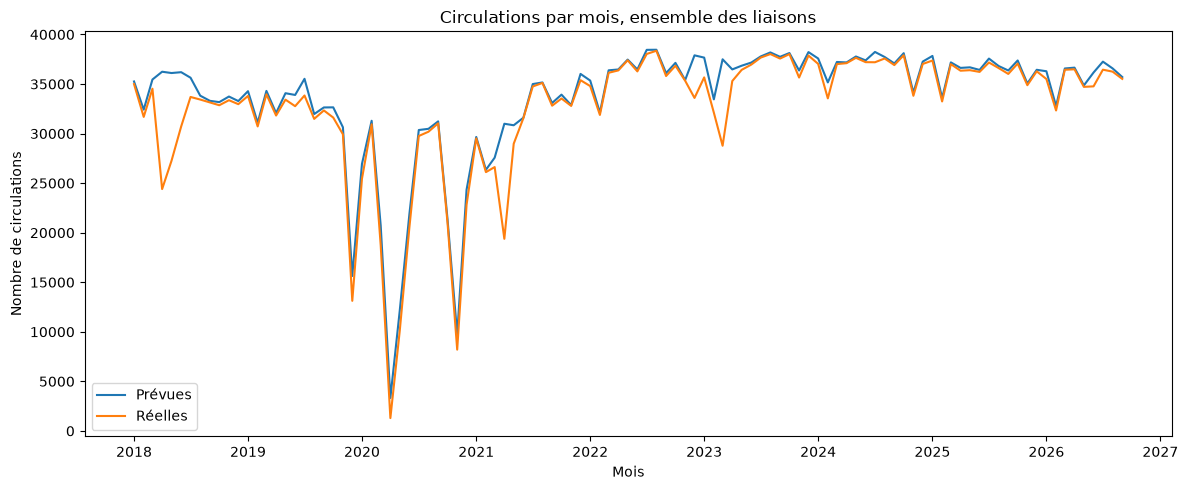

In [17]:
# Circulations prévues, annulées et réelles, additionnées sur toutes les liaisons
trafic = (
    df.assign(Date=pd.to_datetime(df["Date"]))
    .groupby("Date")[["Nombre de circulations prévues", "Nombre de trains annulés"]]
    .sum()
)
trafic["circulations_reelles"] = (
    trafic["Nombre de circulations prévues"] - trafic["Nombre de trains annulés"]
)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(trafic.index, trafic["Nombre de circulations prévues"], label="Prévues")
ax.plot(trafic.index, trafic["circulations_reelles"], label="Réelles")
ax.set_title("Circulations par mois, ensemble des liaisons")
ax.set_xlabel("Mois")
ax.set_ylabel("Nombre de circulations")
ax.legend()
plt.tight_layout()
plt.show()


Dans cette partie, nous regardons l'évolution du nombre de circulations par mois sur l'ensemble des liaisons, pour repérer les baisses et les rapprocher d'événements connus. Nous additionnons les circulations prévues et les circulations réelles (prévues moins annulées) de toutes les liaisons. Un même TGV pouvant compter dans plusieurs liaisons, cette somme ne donne pas le nombre exact de trains, elle sert à suivre l'évolution du volume.

D'après la figure « Circulations par mois, ensemble des liaisons », le nombre de circulations prévues se situe autour de 33 000 à 35 000 par mois en 2018 et 2019, puis autour de 36 000 à 38 000 à partir de 2022. Plusieurs baisses nettes apparaissent. Fin 2019, en avril 2020 et en novembre 2020, les circulations prévues et réelles baissent ensemble, avec un minimum d'environ 3 500 circulations prévues en avril 2020. En avril 2018, en avril 2021 et en mars 2023, seules les circulations réelles baissent fortement, ce qui correspond aux mois d'annulations élevées observés sur Paris - Nantes. Ces pics ne sont donc pas propres à cette liaison.

Ces baisses coïncident avec des événements connus : la grève SNCF du printemps 2018 (3 avril au 28 juin), la grève contre la réforme des retraites de décembre 2019, les trois confinements (17 mars au 11 mai 2020, 30 octobre au 15 décembre 2020 et 3 avril au 3 mai 2021), la grève des contrôleurs de fin décembre 2022 et les journées de mobilisation de mars 2023. Ces rapprochements reposent sur la concordance des dates, et non sur les données du fichier, qui n'indiquent aucune cause. Le mouvement des gilets jaunes, commencé en novembre 2018, ne laisse pas de trace visible dans les circulations mensuelles.


 - 

### 4.4 Définition d'une liaison



Dans ce jeu de données, chaque ligne correspond à un couple (gare de départ, gare d'arrivée) pour un mois donné. Nous gardons cette définition pour définir une liaison. Une liaison est donc ici un couple orienté, et l'aller et le retour sont deux liaisons distinctes. Nous vérifions par la suite que chaque liaison compte au plus une ligne par mois et que son service (national ou international) ne change pas.

In [18]:
# Nombre de liaisons
cle_liaison = ["Gare de départ", "Gare d'arrivée"]
print(f"Nombre de liaisons : {df.groupby(cle_liaison).ngroups}")

# une seule ligne par liaison et par mois
doublons = df.duplicated(subset=cle_liaison + ["Date"], keep=False)
print(f"Lignes en doublon sur (liaison, mois) : {doublons.sum()}")
display(
    df.loc[doublons]
    .sort_values(cle_liaison + ["Date"])[cle_liaison + ["Date", "Service"]]
    .head(10)
)

# le service est-il constant pour une même liaison ?
services_par_liaison = df.groupby(cle_liaison)["Service"].nunique()
print(f"Liaisons avec plus d'un service : {(services_par_liaison > 1).sum()}")
display(services_par_liaison[services_par_liaison > 1].head(10))

# Nombre de mois par liaison
mois_par_liaison = df.groupby(cle_liaison)["Date"].nunique()
display(mois_par_liaison.describe())
print(
    f"Liaisons présentes sur les {df['Date'].nunique()} mois : {(mois_par_liaison == df['Date'].nunique()).sum()}"
)

Nombre de liaisons : 130
Lignes en doublon sur (liaison, mois) : 84


,Gare de départ,Gare d'arrivée,Date,Service
11055,BELLEGARDE (AIN),PARIS LYON,2025-07,National
11130,BELLEGARDE (AIN),PARIS LYON,2025-07,International
11185,BELLEGARDE (AIN),PARIS LYON,2025-08,International
11197,BELLEGARDE (AIN),PARIS LYON,2025-08,National
11320,BELLEGARDE (AIN),PARIS LYON,2025-09,International
11377,BELLEGARDE (AIN),PARIS LYON,2025-09,National
11078,CHAMBERY CHALLES LES EAUX,PARIS LYON,2025-07,International
11137,CHAMBERY CHALLES LES EAUX,PARIS LYON,2025-07,National
11220,CHAMBERY CHALLES LES EAUX,PARIS LYON,2025-08,International
11277,CHAMBERY CHALLES LES EAUX,PARIS LYON,2025-08,National


Liaisons avec plus d'un service : 16


Gare de départ             Gare d'arrivée      
BARCELONA                  PARIS LYON              2
BELLEGARDE (AIN)           PARIS LYON              2
CHAMBERY CHALLES LES EAUX  PARIS LYON              2
DIJON VILLE                PARIS LYON              2
LYON PART DIEU             MARSEILLE ST CHARLES    2
MACON LOCHE                PARIS LYON              2
MARSEILLE ST CHARLES       LYON PART DIEU          2
MULHOUSE VILLE             PARIS LYON              2
PARIS EST                  STRASBOURG              2
PARIS LYON                 BARCELONA               2
Name: Service, dtype: int64

count    130.000000
mean      98.961538
std       22.074716
min       12.000000
25%      105.000000
50%      105.000000
75%      105.000000
max      105.000000
Name: Date, dtype: float64

Liaisons présentes sur les 105 mois : 114


Au vu de ces contrôles, nous complétons la définition précédente. Sur 130 couples de gares, 84 lignes sont en doublon sur (liaison, mois), en juillet, août et septembre 2025, car une même paire de gares apparaît à la fois comme nationale et internationale. Nous ajoutons donc le service à la clé, par suite une liaison est donc un triplet (gare de départ, gare d'arrivée, service), ce qui supprime les doublons. 

### 4.5 Tableau d'indicateurs par liaison

Objectif : calculer, pour chaque liaison, le taux d'annulation, le taux de retard sur trains circulés et le nombre de mois disponibles, en additionnant numérateurs et dénominateurs avant de diviser.

In [19]:
# Colonnes utilisées et clé d'une liaison
col_prevues = "Nombre de circulations prévues"
col_annules = "Nombre de trains annulés"
col_retards = "Nombre de trains en retard à l'arrivée"
cle_service = ["Gare de départ", "Gare d'arrivée", "Service"]

# circulations prévues à 0 ou comptage négatif
exclues = (df[col_prevues] == 0) | (
    df[[col_prevues, col_annules, col_retards]] < 0
).any(axis=1)
print(f"Lignes exclues : {exclues.sum()} sur {len(df)}")
df_indic = df.loc[~exclues].copy()
df_indic["circulations_reelles"] = df_indic[col_prevues] - df_indic[col_annules]

# Sommes par liaison
indicateurs = df_indic.groupby(cle_service).agg(
    mois=("Date", "nunique"),
    prevues=(col_prevues, "sum"),
    annules=(col_annules, "sum"),
    reelles=("circulations_reelles", "sum"),
    retards=(col_retards, "sum"),
)

# Taux calculés sur les sommes
indicateurs["taux_annulation"] = indicateurs["annules"] / indicateurs["prevues"]
indicateurs["taux_retard"] = indicateurs["retards"] / indicateurs["reelles"].where(
    indicateurs["reelles"] > 0
)

# affichage
print(indicateurs.shape)
print(indicateurs[["taux_annulation", "taux_retard"]].isna().sum())
print((indicateurs[["taux_annulation", "taux_retard"]] > 1).sum())
display(indicateurs[["mois", "taux_annulation", "taux_retard"]].describe())

# Contrôle sur Paris - Nantes
display(indicateurs.loc[("PARIS MONTPARNASSE", "NANTES", "National")])
reelles_nantes = df_paris_nantes[col_prevues] - df_paris_nantes[col_annules]
print(df_paris_nantes[col_annules].sum() / df_paris_nantes[col_prevues].sum())
print(df_paris_nantes[col_retards].sum() / reelles_nantes.sum())

Lignes exclues : 73 sur 12907
(146, 7)
taux_annulation    0
taux_retard        0
dtype: int64
taux_annulation    0
taux_retard        0
dtype: int64


,mois,taux_annulation,taux_retard
count,146.000000,146.000000,146.000000
mean,87.904110,0.029131,0.154914
std,36.232074,0.012291,0.061028
min,3.000000,0.000000,0.083592
25%,104.000000,0.024459,0.114730
50%,104.000000,0.029789,0.147867
75%,105.000000,0.034679,0.177480
max,105.000000,0.079656,0.535912


mois                 105.000000
prevues            55803.000000
annules             1625.000000
reelles            54178.000000
retards             6305.000000
taux_annulation        0.029120
taux_retard            0.116376
Name: (PARIS MONTPARNASSE, NANTES, National), dtype: float64

0.029120298191853484
0.11637565063309831


Pour le score de fiabilité, il nous faut aussi un indicateur qui compte à la fois les annulations et les retards. Le taux de perturbation rapporte les trains annulés et les trains en retard à l'arrivée aux circulations prévues. Un train annulé ne peut pas arriver en retard, les deux ne se recoupent donc pas. Nous fixons aussi ici le nombre minimal de mois (24) en dessous duquel une liaison est jugée trop courte pour être comparée.

In [20]:
indicateurs["taux_perturbation"] = (
    indicateurs["annules"] + indicateurs["retards"]
) / indicateurs["prevues"]

seuil_mois = 24
cle_nantes = ("PARIS MONTPARNASSE", "NANTES", "National")

print((indicateurs["taux_perturbation"] > 1).sum())
print((indicateurs["mois"] >= seuil_mois).sum())
display(
    indicateurs.loc[cle_nantes, ["taux_annulation", "taux_retard", "taux_perturbation"]]
)

0
123


taux_annulation      0.029120
taux_retard          0.116376
taux_perturbation    0.142107
Name: (PARIS MONTPARNASSE, NANTES, National), dtype: float64

### 4.6 Profil des causes par liaison

Sur Paris - Nantes, les causes externes arrivent en tête, devant l'infrastructure. Reste à voir si ce profil est courant ou si Nantes fait figure d'exception. Nous reprenons la méthode de la section 3.2 pour chaque liaison : les pourcentages de chaque mois sont convertis en nombres de trains, additionnés sur la période, puis rapportés au total. Une liaison qui compte très peu de retards aura un profil instable, c'est pourquoi les comparaisons ci-dessous se limitent aux liaisons observées sur au moins 24 mois.

In [21]:
volumes_causes = df_indic[cause_cols].mul(df_indic[col_retards], axis=0) / 100
volumes_causes = pd.concat([df_indic[cle_service], volumes_causes], axis=1)

trains_par_cause = volumes_causes.groupby(cle_service)[cause_cols].sum()
parts_causes = 100 * trains_par_cause.div(trains_par_cause.sum(axis=1), axis=0)
parts_causes.columns = noms_courts

print(parts_causes.shape)
print(f"Liaisons sans aucun retard : {parts_causes.isna().any(axis=1).sum()}")
display(parts_causes.loc[cle_nantes].round(1))
display(parts_causes.describe().round(1))

(146, 6)
Liaisons sans aucun retard : 0


Externes                         30.6
Infrastructure                   20.1
Gestion du trafic                15.9
Matériel roulant                 16.4
Gestion en gare                   8.9
Prise en compte des voyageurs     8.2
Name: (PARIS MONTPARNASSE, NANTES, National), dtype: float64

,Externes,Infrastructure,Gestion du trafic,Matériel roulant,Gestion en gare,Prise en compte des voyageurs
count,146.0,146.0,146.0,146.0,146.0,146.0
mean,22.5,20.7,21.5,19.5,8.7,7.0
std,6.6,5.5,8.2,7.4,4.3,3.5
min,5.9,5.9,8.6,1.3,0.0,0.0
25%,18.0,16.7,16.4,14.4,5.4,4.4
50%,22.0,20.7,19.5,17.5,8.3,6.7
75%,26.4,24.5,25.0,24.1,11.9,9.1
max,45.3,32.5,48.5,47.1,23.7,16.8


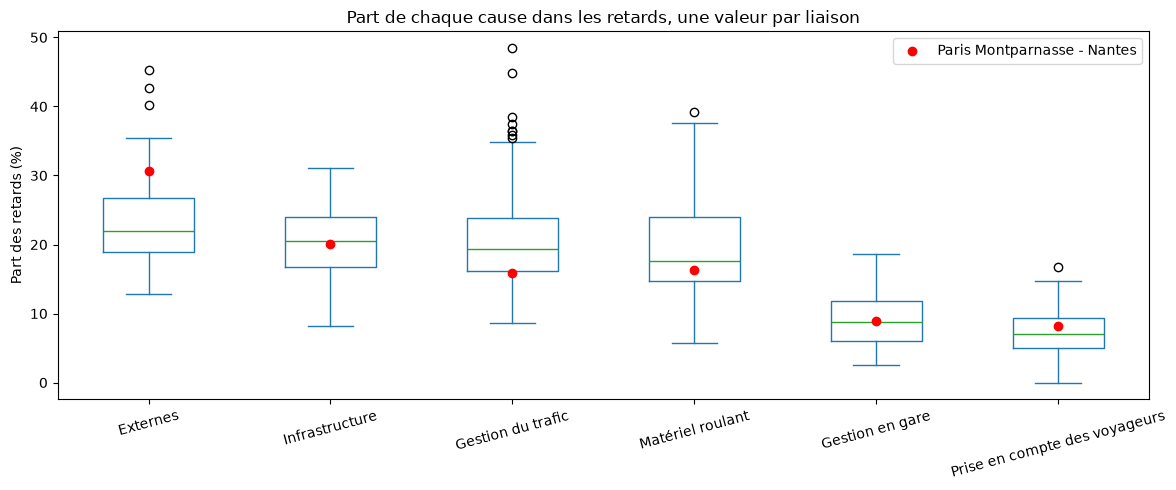

Matériel roulant     36
Externes             34
Gestion du trafic    32
Infrastructure       21
Name: count, dtype: int64

In [22]:
assez_de_mois = indicateurs["mois"] >= seuil_mois

fig, ax = plt.subplots(figsize=(12, 5))
parts_causes.loc[assez_de_mois].plot.box(ax=ax, rot=15)
ax.scatter(
    range(1, 7),
    parts_causes.loc[cle_nantes],
    color="red",
    zorder=3,
    label="Paris Montparnasse - Nantes",
)
ax.set_title("Part de chaque cause dans les retards, une valeur par liaison")
ax.set_ylabel("Part des retards (%)")
ax.legend()
plt.tight_layout()
plt.show()

cause_dominante = parts_causes.dropna(how="all").idxmax(axis=1)
display(cause_dominante[assez_de_mois].value_counts())

La figure « Part de chaque cause dans les retards, une valeur par liaison » présente, pour chaque cause, la répartition de sa part sur les liaisons observées au moins 24 mois. Le point rouge est la liaison Paris - Nantes, une liaison qu'on a étudiée dans les sections précédentes. 

Cette liaison est proche de la médiane pour l'infrastructure, la gestion en gare et la prise en compte des voyageurs. Ses causes externes (30,6 %) dépassent le troisième quartile, alors que la gestion du trafic (15,9 %) et le matériel roulant (16,4 %) sont un peu sous leurs médianes.

Aucune cause ne domine sur le réseau. Sur 123 liaisons, la première cause est le matériel roulant pour 36, les causes externes pour 34, la gestion du trafic pour 32 et l'infrastructure pour 21. La gestion en gare et la prise en compte des voyageurs ne sont jamais en tête. Les écarts entre liaisons sont larges, par exemple de 5,9 % à 45,3 % pour les causes externes. Les données ne disent pas à quoi tient cette diversité.

### 4.7 Mois de choc national

Avril 2020 n'apprend rien sur la fiabilité propre d'une liaison, puisque tout le réseau était touché. Avant d'étudier la saisonnalité et la régularité, nous repérons donc les mois où le taux de perturbation de l'ensemble des liaisons est anormalement élevé.

Pour un mois $t$ et une liaison $i$, notons $A_{i,t}$ le nombre de trains annulés, $R_{i,t}$ le nombre de trains en retard à l'arrivée et $P_{i,t}$ le nombre de circulations prévues. Le taux de perturbation national du mois $t$ est calculé en additionnant les effectifs de toutes les liaisons avant de diviser :

$$\tau_t = \frac{\sum_i \left(A_{i,t} + R_{i,t}\right)}{\sum_i P_{i,t}}$$

Nous appliquons la règle des 3 sigmas dans sa version robuste (filtre de Hampel). Soit $m$ la médiane des $\tau_t$ et $\operatorname{MAD}$ l'écart absolu médian :

$$m = \operatorname{med}_t\left(\tau_t\right), \qquad \operatorname{MAD} = \operatorname{med}_t\left(\left|\tau_t - m\right|\right), \qquad \hat{\sigma} = 1{,}4826 \times \operatorname{MAD}$$

Un mois $t$ est dit de choc national si

$$\tau_t > m + 3\,\hat{\sigma}$$

La médiane et l'écart absolu médian remplacent la moyenne et l'écart-type, car les chocs faussent ces deux derniers. Le facteur $1{,}4826 = 1/\Phi^{-1}(3/4)$, où $\Phi$ est la fonction de répartition de la loi normale centrée réduite, rend $\hat{\sigma}$ comparable à un écart-type lorsque les données sont normales. Nous retenons 3 sigmas plutôt que 2 pour ne garder que les chocs nets, et nous contrôlons le résultat avec les événements de la section 4.3.

Nous écartons ces mois de l'étude de la saisonnalité et de la régularité, qui cherchent à décrire le comportement propre d'une liaison. Un cycle annuel revient chaque année au même moment, alors qu'avril 2018, avril 2020 et avril 2021 sont trois événements distincts : les garder ferait apparaître un « mois d'avril mauvais » qui n'a rien de saisonnier. De même, en avril 2020, presque toutes les liaisons ont eu leur pire mois en même temps, et sans retrait elles paraîtraient presque toutes « accidentelles » pour la même raison. Ces mois ne sont pas supprimés du score de fiabilité, car un assureur est exposé à ces événements.

Sources : Leys, C., Ley, C., Klein, O., Bernard, P. et Licata, L. (2013), « Detecting outliers: Do not use standard deviation around the mean, use absolute deviation around the median », *Journal of Experimental Social Psychology*, 49(4), 764-766 ([notice](https://orbilu.uni.lu/handle/10993/59204)). Pour le facteur 1,4826 : [Statistics By Jim, Median Absolute Deviation](https://statisticsbyjim.com/basics/median-absolute-deviation/).

In [ ]:
df_indic["Date"] = pd.to_datetime(df_indic["Date"])
df_indic["annee"] = df_indic["Date"].dt.year
df_indic["mois_cal"] = df_indic["Date"].dt.month

somme_cols = [col_prevues, col_annules, col_retards, "circulations_reelles"]
mensuel = df_indic.groupby("Date")[somme_cols].sum()
mensuel["taux_annulation"] = mensuel[col_annules] / mensuel[col_prevues]
mensuel["taux_retard"] = mensuel[col_retards] / mensuel["circulations_reelles"]
mensuel["taux_perturbation"] = (mensuel[col_annules] + mensuel[col_retards]) / mensuel[
    col_prevues
]

mediane = mensuel["taux_perturbation"].median()
ecart_robuste = 1.4826 * (mensuel["taux_perturbation"] - mediane).abs().median()
seuil_choc = mediane + 3 * ecart_robuste
mois_choc = mensuel.index[mensuel["taux_perturbation"] > seuil_choc]

print(f"Seuil de choc : {seuil_choc:.3f}")
print(f"Mois de choc : {len(mois_choc)} sur {len(mensuel)}")
display(
    mensuel.loc[
        mois_choc, ["taux_annulation", "taux_retard", "taux_perturbation"]
    ].round(3)
)

Seuil de choc : 0.287
Mois de choc : 8 sur 105


,taux_annulation,taux_retard,taux_perturbation
Date,,,
2018-04-01,0.327,0.167,0.439
2018-05-01,0.245,0.173,0.376
2018-06-01,0.151,0.211,0.331
2018-07-01,0.054,0.264,0.305
2019-12-01,0.160,0.178,0.310
2020-04-01,0.472,0.317,0.639
2021-04-01,0.375,0.061,0.413
2023-03-01,0.233,0.134,0.335


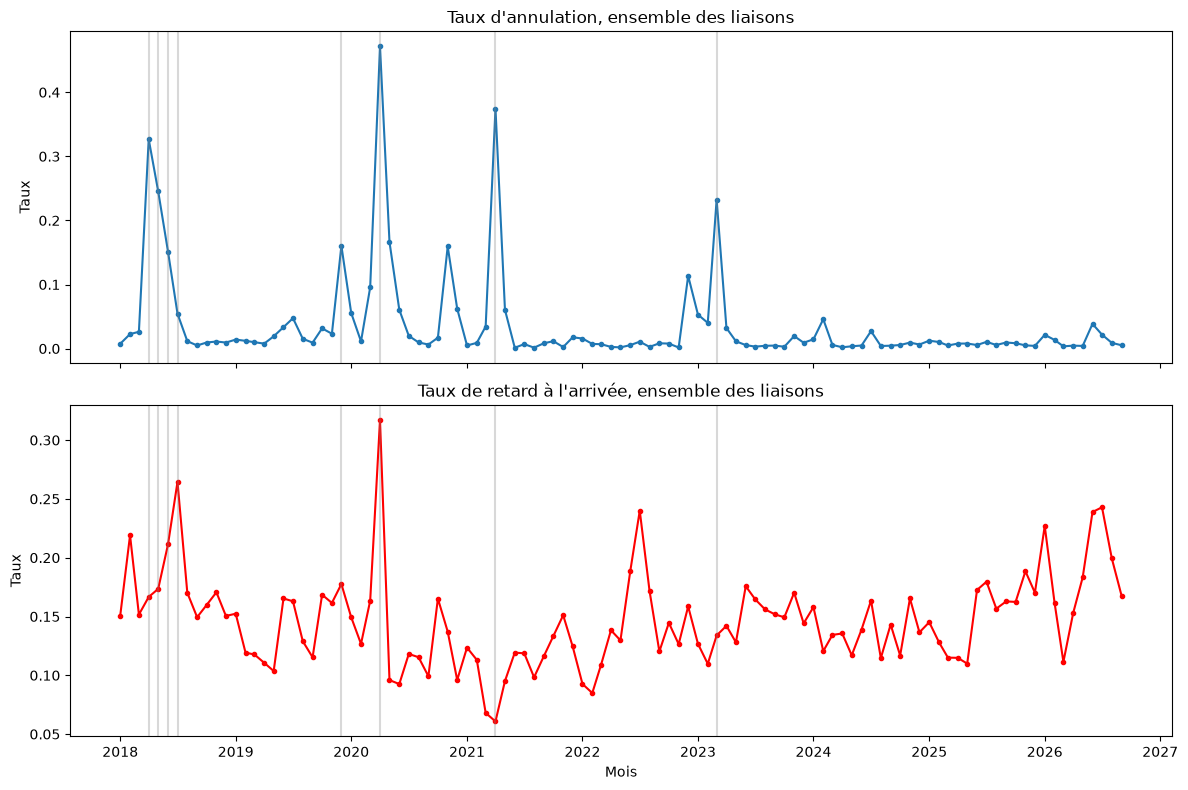

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(mensuel.index, mensuel["taux_annulation"], marker="o", markersize=3)
axes[0].set_title("Taux d'annulation, ensemble des liaisons")
axes[0].set_ylabel("Taux")

axes[1].plot(mensuel.index, mensuel["taux_retard"], marker="o", markersize=3, color="r")
axes[1].set_title("Taux de retard à l'arrivée, ensemble des liaisons")
axes[1].set_ylabel("Taux")
axes[1].set_xlabel("Mois")

for ax in axes:
    for m in mois_choc:
        ax.axvline(m, color="grey", alpha=0.3)

plt.tight_layout()
plt.show()

La figure présente les taux d'annulation (en haut) et de retard à l'arrivée (en bas) de l'ensemble des liaisons. Les traits gris marquent les huit mois de choc national sur 105, dont le taux de perturbation dépasse 28,7 %.

Ces mois correspondent aux événements de la section 4.3 : avril à juillet 2018, décembre 2019, avril 2020, avril 2021 et mars 2023. Ils sont presque tous retenus pour leurs annulations, sauf juillet 2018, retenu pour son taux de retard (26,4 %). Les annulations de novembre 2020 et de décembre 2022 restent sous le seuil et ne sont pas retirées des calculs suivants.

Ces huit mois seront donc écartés de l'étude de la saisonnalité et de la régularité, et conservés dans le score de fiabilité.

### 4.8 Saisonnalité

Sur la liaison Paris Montparnasse - Nantes, aucune colonne de la heatmap ne restait foncée d'une année à l'autre. Qu'en est-il pour l'ensemble du réseau ? Nous regardons d'abord le taux de retard national année par année, puis le profil moyen de chaque mois calendaire une fois les mois de choc retirés, car ils tireraient artificiellement certains mois vers le haut.

Une hypothèse de départ, à vérifier : les annulations viendraient surtout de chocs ponctuels, alors que les retards pourraient suivre un cycle annuel (affluence en été, météo en hiver, travaux planifiés par période). Le fichier ne contient rien sur ces causes, ce n'est donc qu'une piste.

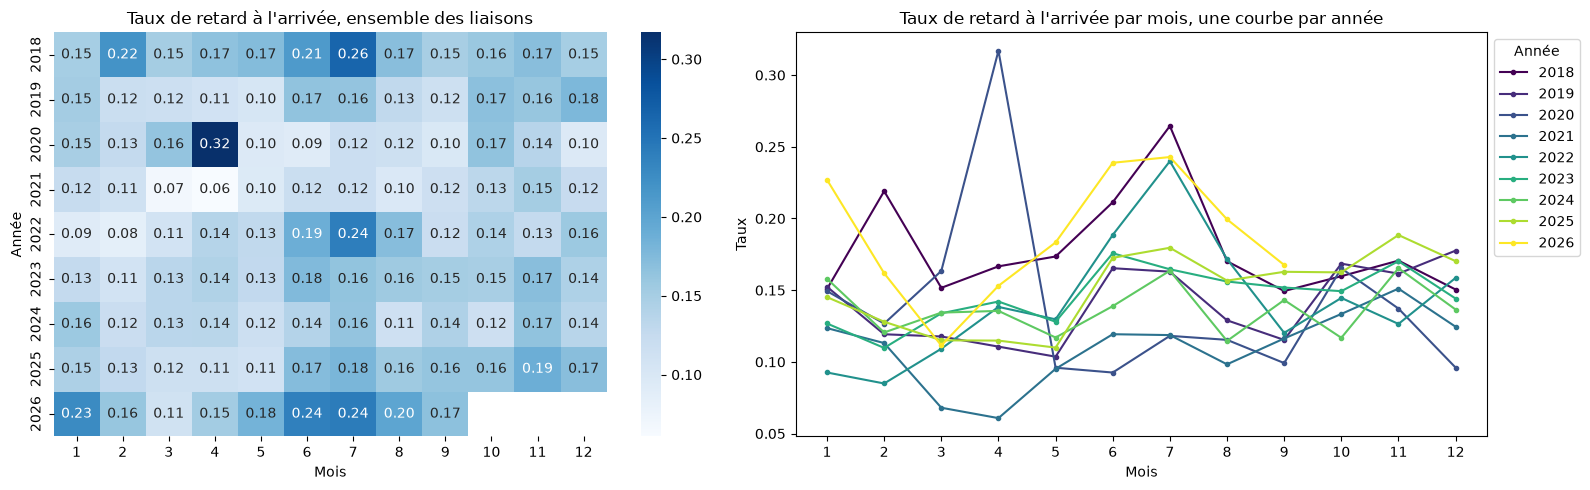

In [ ]:
table_nationale = mensuel.assign(
    annee=mensuel.index.year, mois_cal=mensuel.index.month
).pivot(index="annee", columns="mois_cal", values="taux_retard")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.heatmap(table_nationale, annot=True, fmt=".2f", cmap="Blues", ax=axes[0])
axes[0].set_title("Taux de retard à l'arrivée, ensemble des liaisons")
axes[0].set_xlabel("Mois")
axes[0].set_ylabel("Année")

table_nationale.T.plot(ax=axes[1], colormap="viridis", marker="o", markersize=3)
axes[1].set_title("Taux de retard à l'arrivée par mois, une courbe par année")
axes[1].set_xlabel("Mois")
axes[1].set_ylabel("Taux")
axes[1].set_xticks(range(1, 13))
axes[1].legend(title="Année", loc="upper left", bbox_to_anchor=(1, 1))

plt.tight_layout()
plt.show()

La figure « Taux de retard à l'arrivée, ensemble des liaisons » présente, à gauche, le taux national année par année et mois par mois, et à droite les mêmes valeurs avec une courbe par année. Les mois les plus sombres sont des chocs, comme avril 2020 (32 %). En dehors d'eux, juin et juillet restent au-dessus du niveau habituel presque chaque année, avec les exceptions de 2020 et 2021. Cette première lecture suggère à un cycle des retards, que le profil moyen ci-dessous permet de préciser.

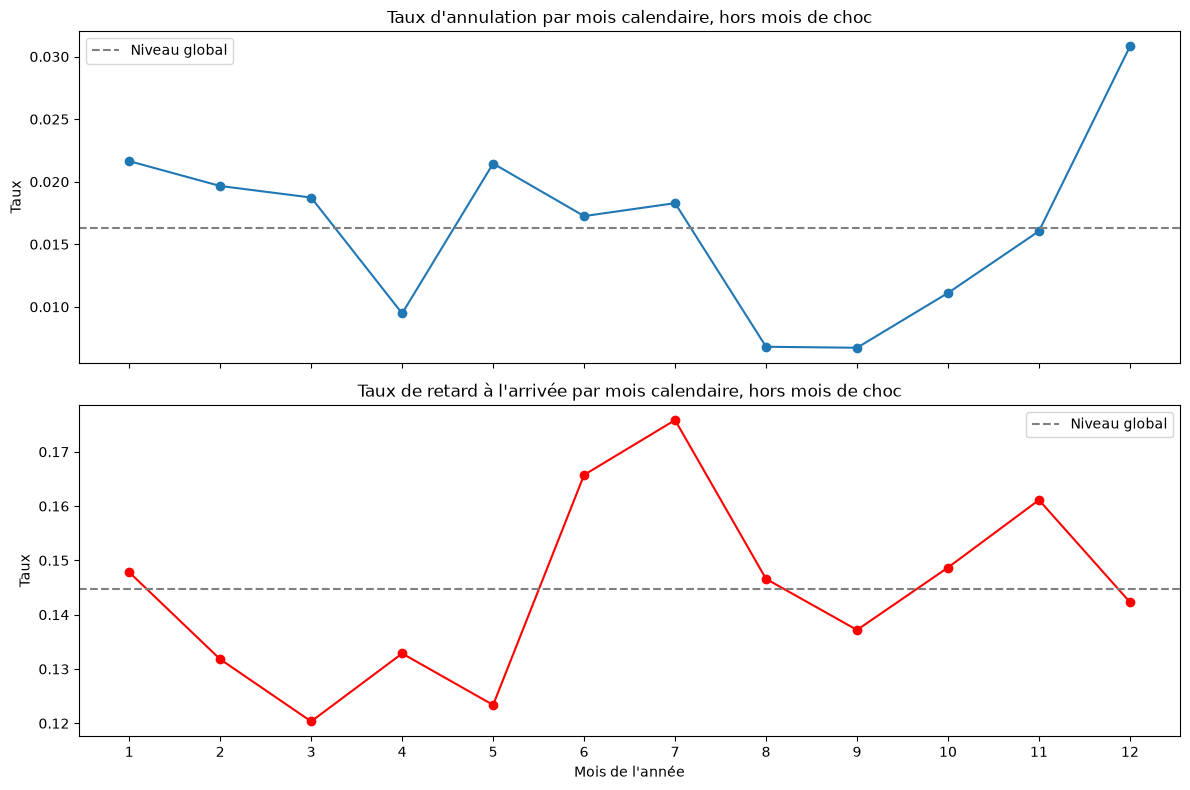

In [26]:
hors_chocs = mensuel.drop(index=mois_choc)
profil = hors_chocs.groupby(hors_chocs.index.month)[somme_cols].sum()
profil["taux_annulation"] = profil[col_annules] / profil[col_prevues]
profil["taux_retard"] = profil[col_retards] / profil["circulations_reelles"]

niveau_annulation = hors_chocs[col_annules].sum() / hors_chocs[col_prevues].sum()
niveau_retard = hors_chocs[col_retards].sum() / hors_chocs["circulations_reelles"].sum()

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(profil.index, profil["taux_annulation"], marker="o")
axes[0].axhline(niveau_annulation, color="grey", linestyle="--", label="Niveau global")
axes[0].set_title("Taux d'annulation par mois calendaire, hors mois de choc")
axes[0].set_ylabel("Taux")
axes[0].legend()

axes[1].plot(profil.index, profil["taux_retard"], marker="o", color="r")
axes[1].axhline(niveau_retard, color="grey", linestyle="--", label="Niveau global")
axes[1].set_title("Taux de retard à l'arrivée par mois calendaire, hors mois de choc")
axes[1].set_ylabel("Taux")
axes[1].set_xlabel("Mois de l'année")
axes[1].set_xticks(range(1, 13))
axes[1].legend()

plt.tight_layout()
plt.show()

La figure « Taux par mois calendaire, hors mois de choc » présente, pour les annulations (en haut) et les retards (en bas), le niveau moyen de chaque mois de l'année, avec le niveau global en pointillés. On remarque que le taux de retard est plus haut en juillet (environ 17,6 %) et en juin, et le plus bas de mars à mai (autour de 12 à 13 %), pour un niveau global proche de 14,5 %. L'écart entre le meilleur et le pire mois est d'environ 5 points, soit plus d'un tiers du niveau global, ce qui suggère une saisonnalité des retards.

Les annulations se comportent autrement. Leur taux est le plus élevé en décembre (environ 3 %, presque le double du niveau global) et le plus bas en août et septembre. Ce pic qu'on observe en décembre pourrait potentielllement venir d'une seule année, puisque décembre 2022 (grève des contrôleurs) n'a pas été retiré. Le dataset que nous disposons ne permet pas d'établir la cause de ces variations.

Le réseau pris dans son ensemble peut masquer des comportements opposés. Pour savoir si la saisonnalité vaut pour toutes les liaisons, nous mesurons, pour chacune (24 mois au moins, mois de choc retirés), quelle part de la variation de son taux de retard mensuel s'explique par le seul mois de l'année. Proche de 0, le mois de l'année n'apporte rien. Proche de 1, les mois se répètent d'une année sur l'autre. La mesure est corrigée du nombre de mois observés, faute de quoi une série courte paraîtrait saisonnière par simple hasard.

In [27]:
df_hors_chocs = df_indic.loc[~df_indic["Date"].isin(mois_choc)].copy()
df_hors_chocs["taux_retard_mensuel"] = df_hors_chocs[col_retards] / df_hors_chocs[
    "circulations_reelles"
].where(df_hors_chocs["circulations_reelles"] > 0)

groupes_hors_chocs = dict(tuple(df_hors_chocs.groupby(cle_service)))

resultats = {}
for cle, groupe in groupes_hors_chocs.items():
    y = groupe["taux_retard_mensuel"].dropna()
    n = len(y)
    mois_obs = groupe.loc[y.index, "mois_cal"]
    k = mois_obs.nunique()
    total = ((y - y.mean()) ** 2).sum()
    if n < seuil_mois or total == 0 or n <= k:
        resultats[cle] = np.nan
        continue
    moyennes = y.groupby(mois_obs).transform("mean")
    r2 = ((moyennes - y.mean()) ** 2).sum() / total
    resultats[cle] = 1 - (1 - r2) * (n - 1) / (n - k)

saisonnalite = pd.Series(resultats, name="saisonnalite")
saisonnalite.index.names = cle_service

print(saisonnalite.notna().sum())
display(saisonnalite.describe().round(3))
print(f"Paris - Nantes : {saisonnalite.loc[cle_nantes]:.3f}")

123


count    123.000
mean       0.078
std        0.100
min       -0.100
25%        0.005
50%        0.055
75%        0.135
max        0.355
Name: saisonnalite, dtype: float64

Paris - Nantes : -0.047


La part de variation du taux de retard mensuel expliquée par le mois de l'année a été calculée pour 123 liaisons. Elle est faible : la médiane est de 0,055, les trois quarts des liaisons sont sous 0,135 et le maximum atteint 0,355. Pour la liaison Paris Montparnasse - Nantes, la valeur est de −0,047, soit aucun effet saisonnier.

Ce résultat nuance le profil national, où juin et juillet ressortaient. Un écart de niveau entre mois peut donc exister sans que le mois de l'année explique beaucoup de la variation, si les retards varient surtout d'un mois à l'autre pour d'autres raisons.

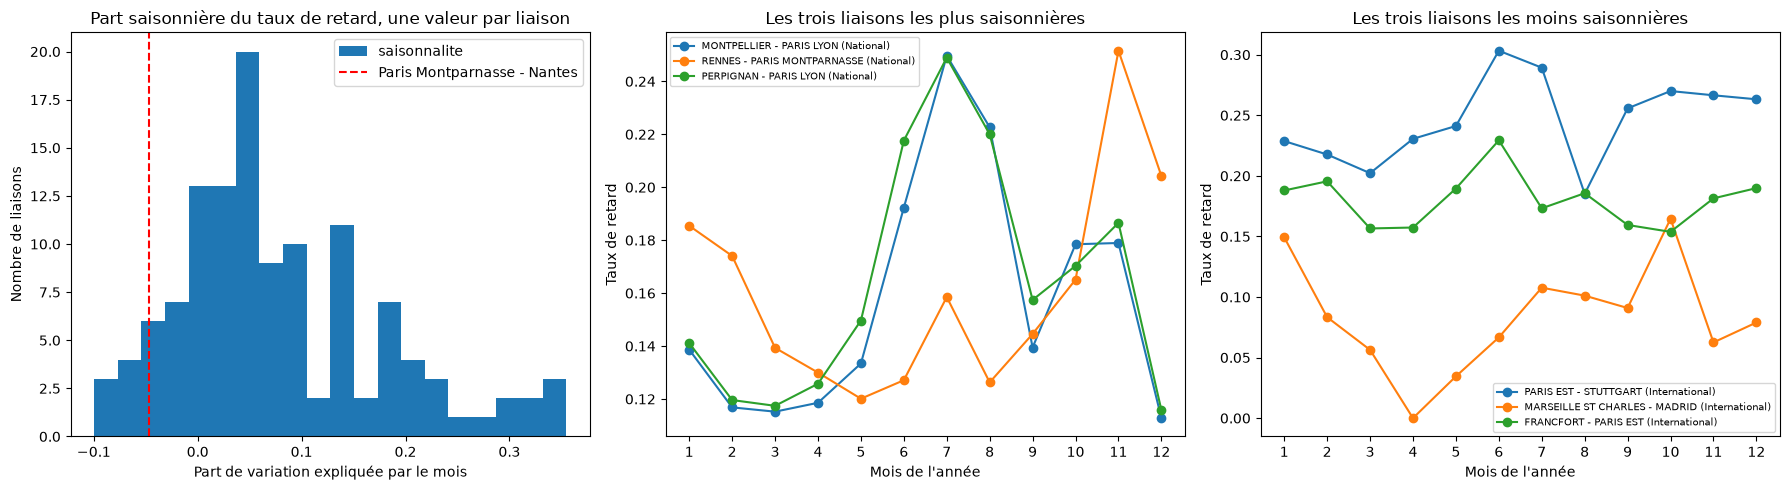

In [28]:
plus_saisonnieres = saisonnalite.dropna().nlargest(3).index
moins_saisonnieres = saisonnalite.dropna().nsmallest(3).index

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

saisonnalite.dropna().plot.hist(bins=20, ax=axes[0])
axes[0].axvline(
    saisonnalite.loc[cle_nantes],
    color="red",
    linestyle="--",
    label="Paris Montparnasse - Nantes",
)
axes[0].set_title("Part saisonnière du taux de retard, une valeur par liaison")
axes[0].set_xlabel("Part de variation expliquée par le mois")
axes[0].set_ylabel("Nombre de liaisons")
axes[0].legend()

for ax, selection, titre in [
    (axes[1], plus_saisonnieres, "Les trois liaisons les plus saisonnières"),
    (axes[2], moins_saisonnieres, "Les trois liaisons les moins saisonnières"),
]:
    for cle in selection:
        g = groupes_hors_chocs[cle]
        par_mois = g.groupby("mois_cal")[[col_retards, "circulations_reelles"]].sum()
        ax.plot(
            par_mois.index,
            par_mois[col_retards] / par_mois["circulations_reelles"],
            marker="o",
            label=f"{cle[0]} - {cle[1]} ({cle[2]})",
        )
    ax.set_title(titre)
    ax.set_xlabel("Mois de l'année")
    ax.set_ylabel("Taux de retard")
    ax.set_xticks(range(1, 13))
    ax.legend(fontsize=7)

plt.tight_layout()
plt.show()

La figure « Part saisonnière du taux de retard, une valeur par liaison » présente à gauche la répartition de la part de variation du taux de retard expliquée par le mois de l'année, sur 123 liaisons, puis les profils mensuels des trois liaisons les plus et les moins saisonnières.

On remarque que cette part est faible, la médiane est de 0,055 et le maximum de 0,355. La liaison Paris Montparnasse - Nantes (−0,047) n'a donc pas d'effet saisonnier. Les plus saisonnières, Montpellier - Paris Lyon et Perpignan - Paris Lyon, ont un pic en juillet-août. Rennes - Paris Montparnasse a son pic en novembre. Par conséquent, la saisonnalité diffère d'une liaison à l'autre. Les trois moins saisonnières sont internationales, probablement avec peu de circulations.

### 4.9 Régularité dans le temps

Nous voulons savoir si le risque d'une liaison revient régulièrement ou s'il vient de quelques mois exceptionnels. L'idée consiste à regarder où tombent les perturbations. Si elles se répartissent sur tous les mois, le risque est répétitif. Si elles se concentrent sur quelques mois, il est plutôt accidentel.

Pour chaque liaison, nous classons les mois du plus au moins perturbé (taux de perturbation), nous retenons les 10 % de mois les plus perturbés (arrondis à l'entier supérieur) et nous calculons la part du total des perturbations, annulés et retards à l'arrivée, qui s'y trouve. Avec des mois tous semblables, cette part serait voisine de 10 %. Plus elle monte, plus le risque est accidentel. Le calcul est fait deux fois, avec tous les mois puis sans les mois de choc national, ce qui permet de mesurer ce que les chocs communs à tout le réseau changent au résultat.

In [29]:
part_pires = 0.10
groupes_liaisons = dict(tuple(df_indic.groupby(cle_service)))


def part_dans_pires_mois(groupe, mois_a_retirer=()):
    g = groupe.loc[~groupe["Date"].isin(mois_a_retirer)]
    perturbes = g[col_annules] + g[col_retards]
    taux = perturbes / g[col_prevues]
    total = perturbes.sum()
    if len(g) < seuil_mois or total == 0:
        return np.nan
    k = int(np.ceil(part_pires * len(g)))
    pires = taux.nlargest(k).index
    return perturbes.loc[pires].sum() / total


regularite = pd.concat(
    {
        "pires_mois_tous": pd.Series(
            {cle: part_dans_pires_mois(g) for cle, g in groupes_liaisons.items()}
        ),
        "pires_mois_hors_chocs": pd.Series(
            {
                cle: part_dans_pires_mois(g, mois_choc)
                for cle, g in groupes_liaisons.items()
            }
        ),
    },
    axis=1,
)
regularite.index.names = cle_service

print(regularite.notna().sum())
display(regularite.describe().round(3))
display(regularite.loc[cle_nantes].round(3))

pires_mois_tous          123
pires_mois_hors_chocs    123
dtype: int64


,pires_mois_tous,pires_mois_hors_chocs
count,123.000,123.000
mean,0.209,0.178
std,0.039,0.030
min,0.143,0.128
25%,0.181,0.160
50%,0.202,0.172
75%,0.231,0.188
max,0.379,0.321


pires_mois_tous          0.195
pires_mois_hors_chocs    0.177
Name: (PARIS MONTPARNASSE, NANTES, National), dtype: float64

La part des perturbations qui tombe dans les 10 % de mois les plus perturbés a été calculée pour 123 liaisons. On remarque qu'elle est supérieure à 10 % pour toutes, avec une médiane de 0,202 en gardant tous les mois et de 0,172 sans les mois de choc. Le retrait des chocs fait donc baisser la concentration d'environ 3 points en moyenne (0,209 contre 0,178). Pour la liaison Paris Montparnasse - Nantes, la baisse est plus faible (0,195 contre 0,177).

Les valeurs sont proches d'une liaison à l'autre (écart-type de 0,030 hors chocs), avec un maximum de 0,321. Par conséquent, le risque est plutôt répétitif pour la majorité des liaisons, avec quelques cas plus accidentels. Une série qui varie un peu d'un mois à l'autre dépasse toujours 10 %, c'est pourquoi on compare surtout les liaisons entre elles.

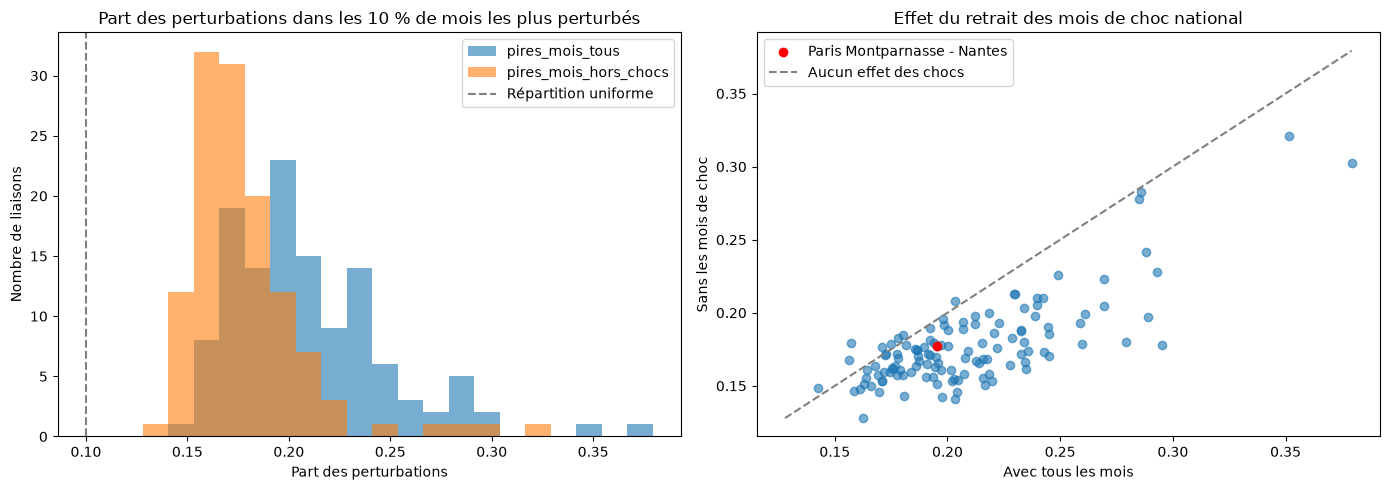

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

regularite.plot.hist(bins=20, alpha=0.6, ax=axes[0])
axes[0].axvline(part_pires, color="grey", linestyle="--", label="Répartition uniforme")
axes[0].set_title("Part des perturbations dans les 10 % de mois les plus perturbés")
axes[0].set_xlabel("Part des perturbations")
axes[0].set_ylabel("Nombre de liaisons")
axes[0].legend()

axes[1].scatter(
    regularite["pires_mois_tous"], regularite["pires_mois_hors_chocs"], alpha=0.6
)
axes[1].scatter(
    regularite.loc[cle_nantes, "pires_mois_tous"],
    regularite.loc[cle_nantes, "pires_mois_hors_chocs"],
    color="red",
    label="Paris Montparnasse - Nantes",
)
borne = [regularite.min().min(), regularite.max().max()]
axes[1].plot(borne, borne, color="grey", linestyle="--", label="Aucun effet des chocs")
axes[1].set_title("Effet du retrait des mois de choc national")
axes[1].set_xlabel("Avec tous les mois")
axes[1].set_ylabel("Sans les mois de choc")
axes[1].legend()

plt.tight_layout()
plt.show()

La figure présente à gauche la répartition, sur 123 liaisons, de la part des perturbations qui tombe dans les 10 % de mois les plus perturbés, avec tous les mois puis sans les mois de choc, et à droite la comparaison des deux valeurs pour chaque liaison.

On remarque que toutes les liaisons sont au-dessus des 10 % d'une répartition uniforme. La médiane est de 0,202 avec tous les mois et de 0,172 sans les chocs, donc le retrait des chocs fait baisser la concentration d'environ 3 points en moyenne. Presque tous les points sont sous la diagonale, et la liaison Paris Montparnasse - Nantes (0,195 contre 0,177) est au cœur du nuage. Deux liaisons se distinguent par une part très élevée avec tous les mois (0,35 et 0,38) et restent autour de 0,30 sans les chocs, ce qui indique un risque accidentel qui ne vient pas des chocs nationaux. Par conséquent, le risque est plutôt répétitif pour la majorité des liaisons, avec quelques cas accidentels. 

## 5. Comparaison des liaisons

### 5.1 Tableau commun et position de Nantes

Les indicateurs calculés séparément sont réunis dans un seul tableau, une ligne par liaison. Seules les liaisons observées sur au moins 24 mois sont comparées, les autres manquent de recul. Pour situer Nantes, nous regardons son rang parmi elles, sur une échelle de 0 (la plus basse valeur) à 1 (la plus haute).

In [ ]:
table_liaisons = indicateurs.join(parts_causes).join(saisonnalite).join(regularite)
table_liaisons["cause_dominante"] = cause_dominante

comparables = table_liaisons[table_liaisons["mois"] >= seuil_mois].copy()
comparables = comparables.dropna(subset=["pires_mois_hors_chocs"])
print(f"{len(table_liaisons)} liaisons au total, {len(comparables)} comparables")

colonnes_rang = [
    "taux_annulation",
    "taux_retard",
    "taux_perturbation",
    "saisonnalite",
    "pires_mois_hors_chocs",
]
display(comparables[colonnes_rang].rank(pct=True).loc[cle_nantes].round(2))

146 liaisons au total, 123 comparables


taux_annulation          0.43
taux_retard              0.26
taux_perturbation        0.26
saisonnalite             0.10
pires_mois_hors_chocs    0.59
Name: (PARIS MONTPARNASSE, NANTES, National), dtype: float64

Le tableau situe la liaison Paris Montparnasse - Nantes parmi les 123 liaisons comparables, par son rang sur une échelle de 0 (la valeur la plus basse) à 1 (la plus haute).

On remarque que son taux de perturbation (0,26) la place parmi les liaisons les moins perturbées : environ trois quarts des liaisons le sont davantage. Cela vient surtout de son taux de retard (0,26), son taux d'annulation étant proche de la médiane (0,43). Sa saisonnalité (0,10) est parmi les plus faibles, et la concentration de ses perturbations sur les pires mois (0,59) est légèrement au-dessus de la médiane. Par conséquent, cette liaison est plutôt fiable, sans cycle saisonnier, avec un risque plus faible que la moyenne.

### 5.2 Niveau de risque et nature du risque

Pour dégager des profils, nous croisons le niveau de perturbation et la régularité hors chocs. Chaque indicateur est coupé à sa médiane parmi les liaisons comparables, ce qui donne quatre cases : plus ou moins perturbée, risque plutôt répétitif ou plutôt accidentel. La coupure à la médiane est une convention de lecture, elle ne signifie pas qu'il existe quatre familles bien séparées. Le nuage de points permettra de juger si les liaisons forment des groupes ou un continuum.

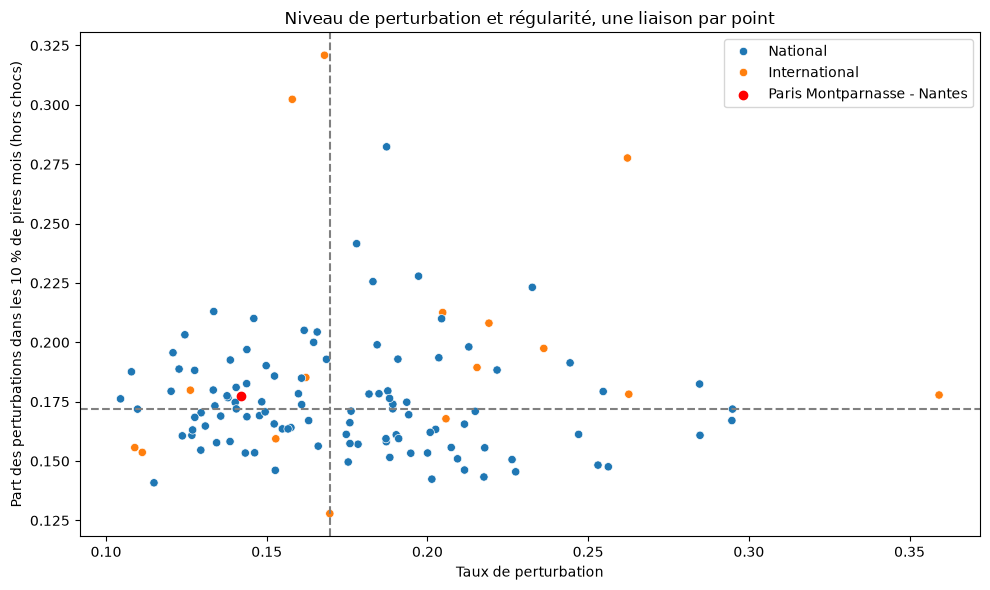

nature,plutôt accidentel,plutôt répétitif
niveau,,
moins perturbée,33,29
plus perturbée,28,33


In [32]:
med_niveau = comparables["taux_perturbation"].median()
med_regul = comparables["pires_mois_hors_chocs"].median()

comparables["niveau"] = np.where(
    comparables["taux_perturbation"] > med_niveau, "plus perturbée", "moins perturbée"
)
comparables["nature"] = np.where(
    comparables["pires_mois_hors_chocs"] > med_regul,
    "plutôt accidentel",
    "plutôt répétitif",
)

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(
    data=comparables.reset_index(),
    x="taux_perturbation",
    y="pires_mois_hors_chocs",
    hue="Service",
    ax=ax,
)
ax.axvline(med_niveau, color="grey", linestyle="--")
ax.axhline(med_regul, color="grey", linestyle="--")
ax.scatter(
    comparables.loc[cle_nantes, "taux_perturbation"],
    comparables.loc[cle_nantes, "pires_mois_hors_chocs"],
    color="red",
    zorder=3,
    label="Paris Montparnasse - Nantes",
)
ax.set_title("Niveau de perturbation et régularité, une liaison par point")
ax.set_xlabel("Taux de perturbation")
ax.set_ylabel("Part des perturbations dans les 10 % de pires mois (hors chocs)")
ax.legend()
plt.tight_layout()
plt.show()

display(comparables.groupby(["niveau", "nature"]).size().unstack())

La figure présente chaque liaison par son taux de perturbation (en abscisse) et la part de ses perturbations tombant dans les 10 % de mois les plus perturbés, hors chocs (en ordonnée). Les pointillés sont les médianes, et le tableau compte les liaisons de chacune des quatre cases.

On remarque que les liaisons ne forment pas de groupes séparés : le nuage est un continuum, dense entre 0,10 et 0,20 en abscisse. Le niveau de perturbation et la nature du risque ne semblent pas liés, car les quatre cases sont proches en effectifs (33, 29, 28 et 33 liaisons). Les liaisons internationales sont dispersées, y compris aux extrémités (taux de perturbation de 0,36, part de 0,32 sur les pires mois). La liaison Paris Montparnasse - Nantes est dans la case moins perturbée et plutôt accidentelle, mais à peine au-dessus de la médiane de régularité.

### 5.3 Causes selon le profil

Les liaisons les plus perturbées ou les plus accidentelles ont-elles un profil de causes différent ? Nous comparons la part moyenne de chaque cause dans les quatre cases. Un écart ne prouve pas que la cause explique le profil, il indique seulement une association que l'on pourra creuser.

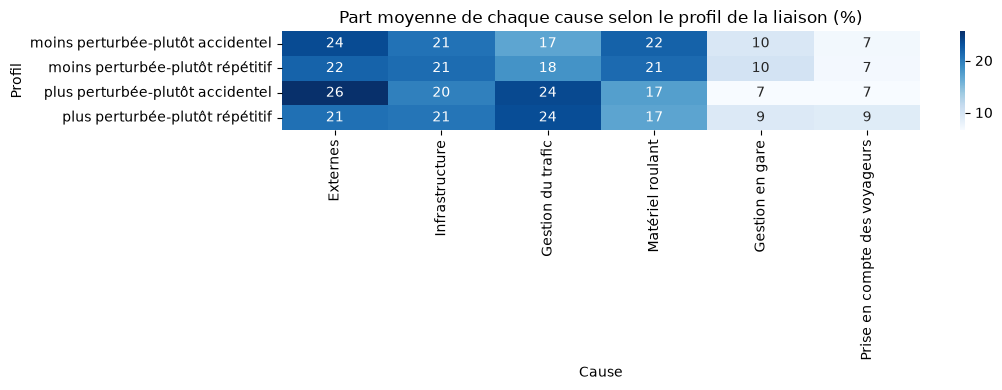

niveau          moins perturbée                     plus perturbée  \
nature        plutôt accidentel plutôt répétitif plutôt accidentel   
row_0                                                                
International                 4                4                 7   
National                     29               25                21   

niveau                          
nature        plutôt répétitif  
row_0                           
International                1  
National                    32

In [33]:
causes_par_profil = comparables.groupby(["niveau", "nature"])[noms_courts].mean()

fig, ax = plt.subplots(figsize=(11, 4))
sns.heatmap(causes_par_profil, annot=True, fmt=".0f", cmap="Blues", ax=ax)
ax.set_title("Part moyenne de chaque cause selon le profil de la liaison (%)")
ax.set_xlabel("Cause")
ax.set_ylabel("Profil")
plt.tight_layout()
plt.show()

display(
    pd.crosstab(
        comparables.index.get_level_values("Service"),
        [comparables["niveau"], comparables["nature"]],
    )
)

La heatmap présente la part moyenne de chaque cause de retard dans les quatre profils de liaisons, et le tableau répartit les liaisons nationales et internationales entre ces profils.

Ce sont les liaisons plus perturbées qui se distinguent le plus. La gestion du trafic y pèse 24 % des retards, contre 17 à 18 % pour les moins perturbées, tandis que le matériel roulant passe de 21-22 % à 17 %. Les causes externes culminent à 26 % pour le profil plus perturbé et plutôt accidentel. L'infrastructure reste stable (20 à 21 %) quel que soit le profil. À niveau de perturbation égal, la nature du risque change peu les parts, donc la cause dominante semble liée au niveau de perturbation plutôt qu'à la régularité.

Côté service, 7 des 8 liaisons internationales les plus perturbées sont plutôt accidentelles, alors que les liaisons nationales se répartissent plus également. Ces effectifs sont petits (16 liaisons internationales au total), donc probablement fragiles. Ces écarts sont des associations, et le dataset n'en donne pas la cause.

## 6. Vers le score de fiabilité

### 6.1 Définition du score

Avant d'écrire les modules, on fixe ici comment le score est calculé, pour que le code ne fasse que suivre ces choix.

Le score part du taux de perturbation $\tau$, la part des trains prévus qui sont annulés ou arrivent en retard :

$$\text{score} = 100 \times \left(1 - \tau\right), \qquad \tau = \frac{\text{annulés} + \text{retards à l'arrivée}}{\text{circulations prévues}}$$

Un train annulé ne peut pas être en retard, donc on peut additionner les deux sans double compte. Le score se lit comme la part des trains prévus qui arrivent normalement. On ne pondère pas selon la gravité du retard, car le dataset ne permet pas de justifier des poids.

La nature du risque (répétitif ou accidentel) vient de la section 4.9, hors mois de choc national. Une liaison observée sur moins de 24 mois garde son score, mais il est signalé comme peu fiable. Pour comparer les liaisons, on ajoute une étiquette par tiers (moins fiable, intermédiaire, plus fiable), dont les bornes sont calculées sur les liaisons ayant assez de recul.

Le score ne dit rien du prix, puisque le dataset ne contient ni tarif ni remboursement. On ne sait pas non plus quel seuil de retard applique la colonne « retards à l'arrivée ». Enfin, il décrit le passé : la prévision est une étape à part.

### 6.2 Calcul du score et de la confiance

In [34]:
table_liaisons["score"] = 100 * (1 - table_liaisons["taux_perturbation"])
table_liaisons["confiance"] = np.where(
    table_liaisons["mois"] >= seuil_mois, "suffisante", "peu fiable"
)

score_reference = table_liaisons.loc[table_liaisons["mois"] >= seuil_mois, "score"]
bornes = score_reference.quantile([1 / 3, 2 / 3])
table_liaisons["tiers"] = pd.cut(
    table_liaisons["score"],
    bins=[-np.inf, bornes.iloc[0], bornes.iloc[1], np.inf],
    labels=["moins fiable", "intermédiaire", "plus fiable"],
)

print(f"Bornes des tiers : {bornes.round(1).tolist()}")
print(f"Score minimum : {table_liaisons['score'].min():.1f}")
print(f"Score maximum : {table_liaisons['score'].max():.1f}")
print(f"Paris - Nantes : {table_liaisons.loc[cle_nantes, 'score']:.1f}")
display(table_liaisons["confiance"].value_counts())
display(table_liaisons["tiers"].value_counts())

Bornes des tiers : [81.0, 85.0]
Score minimum : 44.2
Score maximum : 91.4
Paris - Nantes : 85.8


confiance
suffisante    123
peu fiable     23
Name: count, dtype: int64

tiers
plus fiable      53
moins fiable     47
intermédiaire    46
Name: count, dtype: int64

Les bornes des tiers sont calculées sur les 123 liaisons observées au moins 24 mois : moins fiable sous 81,0, intermédiaire de 81,0 à 85,0 et plus fiable au-dessus de 85,0. Sur les 146 liaisons, 123 ont une confiance suffisante et 23 sont signalées peu fiables.

Les scores vont de 44,2 à 91,4. On remarque que l'intervalle intermédiaire est étroit (4 points), donc un écart de quelques points suffit pour changer de tiers. La liaison Paris Montparnasse - Nantes obtient 85,8, tout juste dans le tiers plus fiable.

### 6.3 Tableau final par liaison

Nous rassemblons ce qui sert à décrire une liaison : le score, sa confiance, les taux, la régularité, la saisonnalité et la cause dominante. Les dix liaisons les moins fiables et les dix plus fiables parmi celles qui ont assez de recul servent de contrôle de cohérence.

In [35]:
colonnes_finales = [
    "mois",
    "confiance",
    "score",
    "tiers",
    "taux_annulation",
    "taux_retard",
    "pires_mois_tous",
    "pires_mois_hors_chocs",
    "saisonnalite",
    "cause_dominante",
]
table_finale = table_liaisons[colonnes_finales].sort_values("score")
fiables = table_finale[table_finale["confiance"] == "suffisante"]

display(fiables.head(10).round(3))
display(fiables.tail(10).round(3))
display(table_finale.loc[[cle_nantes]].round(3))

,,,mois,confiance,score,tiers,taux_annulation,taux_retard,pires_mois_tous,pires_mois_hors_chocs,saisonnalite,cause_dominante
Gare de départ,Gare d'arrivée,Service,,,,,,,,,,
ITALIE,PARIS LYON,International,100,suffisante,64.082,moins fiable,0.043,0.330,0.182,0.178,0.147,Gestion du trafic
LYON PART DIEU,LILLE,National,105,suffisante,70.509,moins fiable,0.041,0.265,0.177,0.172,0.241,Gestion du trafic
CHAMBERY CHALLES LES EAUX,PARIS LYON,National,104,suffisante,70.528,moins fiable,0.032,0.271,0.188,0.167,0.057,Gestion du trafic
LYON PART DIEU,MARNE LA VALLEE,National,104,suffisante,71.519,moins fiable,0.041,0.254,0.179,0.161,0.183,Gestion du trafic
MACON LOCHE,PARIS LYON,National,105,suffisante,71.532,moins fiable,0.031,0.262,0.178,0.182,-0.005,Gestion du trafic
MADRID,MARSEILLE ST CHARLES,International,37,suffisante,73.735,moins fiable,0.080,0.199,0.295,0.178,0.104,Gestion du trafic
PARIS EST,STUTTGART,International,104,suffisante,73.777,moins fiable,0.035,0.236,0.285,0.278,-0.100,Externes
DOUAI,PARIS NORD,National,105,suffisante,74.372,moins fiable,0.045,0.221,0.161,0.148,0.051,Gestion du trafic
LYON PART DIEU,MARSEILLE ST CHARLES,National,105,suffisante,74.532,moins fiable,0.037,0.226,0.194,0.179,0.183,Gestion du trafic


,,,mois,confiance,score,tiers,taux_annulation,taux_retard,pires_mois_tous,pires_mois_hors_chocs,saisonnalite,cause_dominante
Gare de départ,Gare d'arrivée,Service,,,,,,,,,,
DIJON VILLE,PARIS LYON,National,105,suffisante,87.626,plus fiable,0.025,0.101,0.202,0.161,0.134,Infrastructure
PARIS LYON,LE CREUSOT MONTCEAU MONTCHANIN,National,105,suffisante,87.727,plus fiable,0.014,0.110,0.207,0.189,0.047,Matériel roulant
PARIS EST,STRASBOURG,National,105,suffisante,87.916,plus fiable,0.024,0.099,0.198,0.196,0.004,Matériel roulant
BREST,PARIS MONTPARNASSE,National,105,suffisante,87.975,plus fiable,0.032,0.091,0.215,0.179,0.260,Externes
PARIS LYON,DIJON VILLE,National,105,suffisante,88.508,plus fiable,0.025,0.092,0.203,0.141,0.133,Matériel roulant
LAUSANNE,PARIS LYON,International,104,suffisante,88.872,plus fiable,0.029,0.085,0.204,0.154,0.033,Infrastructure
BESANCON FRANCHE COMTE TGV,PARIS LYON,National,105,suffisante,89.019,plus fiable,0.028,0.084,0.233,0.172,0.090,Infrastructure
ZURICH,PARIS LYON,International,104,suffisante,89.106,plus fiable,0.023,0.087,0.216,0.156,0.005,Gestion du trafic
PARIS EST,NANCY,National,105,suffisante,89.209,plus fiable,0.027,0.084,0.233,0.188,0.030,Matériel roulant


,,,mois,confiance,score,tiers,taux_annulation,taux_retard,pires_mois_tous,pires_mois_hors_chocs,saisonnalite,cause_dominante
Gare de départ,Gare d'arrivée,Service,,,,,,,,,,
PARIS MONTPARNASSE,NANTES,National,105,suffisante,85.789,plus fiable,0.029,0.116,0.195,0.177,-0.047,Externes


Le tableau présente les dix liaisons les moins fiables et les dix plus fiables parmi celles à confiance suffisante, puis la ligne de Paris Montparnasse - Nantes.

On remarque que les moins fiables (scores de 64 à 75) ont toutes un taux de retard entre 0,22 et 0,33 et un taux d'annulation entre 3 % et 8 %, contre 0,08 à 0,11 de retard et 1 à 3 % d'annulation pour les plus fiables (scores de 87,6 à 89,5). Le score est donc surtout tiré par les retards. Les liaisons au départ ou à l'arrivée de Lyon (Paris Lyon, Lyon Part-Dieu) apparaissent dans les deux listes, donc le nom d'une gare ne suffit pas à prédire le score. Huit des dix moins fiables ont la gestion du trafic comme première cause, alors que les plus fiables ont plutôt le matériel roulant (5 sur 10) ou l'infrastructure (3 sur 10). Le dataset ne permet pas d'expliquer ce contraste.

### 6.4 Export

Le tableau est exporté en CSV, une ligne par liaison, pour que le reste du groupe et l'application Streamlit puissent le relire sans refaire les calculs.

In [36]:
os.makedirs("outputs", exist_ok=True)
chemin_export = os.path.join("outputs", "scores_liaisons.csv")
table_liaisons.reset_index().to_csv(chemin_export, index=False)
print(chemin_export, table_liaisons.shape)

outputs/scores_liaisons.csv (146, 21)


### 6.5 Limites et suite

Plusieurs points restent ouverts. Les 14 liaisons qui apparaissent à la fois en national et en international de juillet à septembre 2025 sont traitées comme deux liaisons distinctes, et le changement de service coupe en deux les séries de certaines liaisons. Le seuil des mois de choc (trois écarts robustes) et le seuil de 24 mois sont des conventions, dont l'effet reste à tester. Le taux de retard ne dit pas de combien de minutes les trains sont en retard, et la gravité n'entre pas dans le score.

La suite consiste à placer ces calculs dans les modules du projet, avec un test de non-régression sur Paris - Nantes, puis à aborder la prévision en comparant une période aux mêmes mois des années précédentes.